# Generate time series and map subsiding areas in OPERA DISP-S1 products
---    

### About OPERA DISP-S1 (& A Demonstration for WM's Gravel Lab):   

- **Provisional OPERA Level 3 Surface Displacement (DISP-S1) Product from Sentinel-1 at 30m Resolution over North America**
    - The OPERA Level 3 Land-Surface Displacement (L3_DISP) product is generated from a sequence of the Level 2 Coregistered Single Look Complex (L2_CSLC) products derived from Sentinel-1AB (S1) satellites. The OPERA project aims to produce high-quality Interferometric Synthetic Aperture Radar (InSAR)-derived displacement data with reduced decorrelation noise using a hybrid Persistent Scatterer (PS) and Distributed Scatterer (DS) time series processing approach [[dolphin](https://joss.theoj.org/papers/10.21105/joss.06997)]. The displacement product provides information on anthropogenic and natural changes of Earth's surface, such as subsidence, tectonics, and landslides.
    
    - The OPERA project is generating geocoded DISP-S1 products over North America which includes USA and US Territories within 200 km from the US border, Canada, and all mainland countries from the southern US border down to and including Panama. Each pixel within a DISP-S1 frame contains geocoded displacement as well as quality layers information.

    - For more information about the OPERA project and other products please visit our website at https://www.jpl.nasa.gov/go/opera .

- **How we will use this product:**
    - Follow this notebook tutorial to configure and understand how to use this coding environment for our purposes in measuring surface displacement in permafrost landscapes. The example given in this notebook roughly replicates the processes outlined and analyzed in Professor Joanmarie DelVecchio's 2023 paper: https://agupubs.onlinelibrary.wiley.com/doi/full/10.1029/2023JF007156

    - The tutorial will provide at least a basic framework from which we will adapt and use its tools for other coordinates, timeframes, analyses, etc.

    - This notebook is a modified version of a notebook originally created by Dr. Bryan Raimbault, whose work is linked here: https://github.com/OPERA-Cal-Val/OPERA_Applications/blob/main/DISP/Subsidence/DISP-S1_Land_Subsidence.ipynb

---

### OPERA DISP-S1 Data Architecture Overview

The OPERA DISP-S1 products are designed to simplify time series InSAR analysis for a wide user base. Key components of the DISP-S1 architecture:

- **Ministack Structure**  
  - Each file represents cumulative displacement between a fixed reference date** and a specific secondary date
  - A **ministack** includes up to **15 acquisitions**: all files share the same reference date and have different secondary dates  
  - The **last file** in a ministack contains the **total cumulative displacement** from the reference date to the final (15th) secondary date

- **Sequential Ministacks**  
  - The **last secondary date of one ministack becomes the reference date** for the next ministack  
  - This creates a chain of overlapping stacks, where each new ministack starts at zero and spans the next 15 acquisitions

- **Spatial Referencing**  
  - Data is projected in the UTM zone appropriate to each frame  
  - Gridded at **30 m resolution**

- **Data Format & Layers**  
  - Provided as NetCDF files using CF-1.8 conventions
  - Contain:
    - Primary displacement data (`displacement`)
    - Quality metrics (`temporal_coherence`, `phase_similarity`, etc.)
    - Ancillary layers (`recommended_mask`, `water_mask`, `persistent_scatterer_mask`, etc.)
    - Spatial metadata (projection, pixel spacing, etc.)

- **Coverage & Frequency**  
  - Data available over North America, with a 6- to 12-day revisit depending on Sentinel-1 satellite orbit configuration  
  - Products are released as provisional, pending further validation

---

### OPERA DISP-S1 File Naming Convention

Each DISP-S1 product file follows a standardized naming pattern that encodes key metadata directly in the filename.

#### Example:
**OPERA_L3_DISP-S1_IW_F11116_VV_20240406T140838Z_20241003T140837Z_v1.1_20250220T140455Z.nc**

#### Field Descriptions:
- `OPERA_L3_DISP-S1` — OPERA Level-3 Displacement product from Sentinel-1
- `IW` — Interferometric Wide swath mode (Sentinel-1 acquisition mode)
- `<FRAMEID>` — Unique frame identifier (e.g., `F11116`)
- `<POL>` — Polarization used (`VV` or `VH`)
- `<REFDATE>` — Start date of the time series (reference date)
- `<SECONDDATE>` — End date of the time series (last acquisition in ministack)
- `<VERSION>` — Product version (e.g., `v1.1`)
- `<COMPUTEDATE>` — Date the product was generated

#### Notes:
- All displacement values in the file are **cumulative**, measured from `<REFDATE>` to `<SECONDDATE>`.
- Products with different `<REFDATE>` values represent separate ministacks.


Please refer to the [OPERA Product Specification Document](https://d2pn8kiwq2w21t.cloudfront.net/documents/OPERA_DISP_S1_Final_Product_Spec.pdf) for more details about the DISP-S1 products.

*Original tutorial prepared by B. Raimbault using notebook contributions and python packages from M. Govorcin, and S. Staniewicz*  
*- Adapted by D. Bunich to fit the purpose and methodologies of the W&M Gravel Lab's analyses*
</div>

## Setup your conda environment

This step is for users who want to work through a Jupyter Notebook server interface.

Assuming you have [miniconda](https://docs.conda.io/projects/miniconda/en/latest/miniconda-install.html) or conda installed. Open your terminal and run the following:
```
> conda create -n opera_disp-s1
> conda activate opera_disp-s1
> conda install -c conda-forge python==3.12 jupyter ipyleaflet
>  jupyter-notebook /path/to/your.file/Intro_to_DISP-S1.ipynb
```

---    

## Import Libraries

In [23]:
import os
import subprocess
import sys

def run(cmd):
    """Run a shell command silently."""
    subprocess.run(cmd, shell=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

def install_dependencies():
    """Clone and install MintPy and disp-xr with necessary adjustments."""
    run("git clone https://github.com/insarlab/MintPy.git")
    run("pip install -e ./MintPy")

    run("git clone https://github.com/opera-adt/disp-xr.git")
    run("pip install -e ./disp-xr")
    
    run("pip install matplotlib ipykernel pandas rasterio rioxarray asf_search opera_utils zarr s3fs dem_stitcher tile_mate" \
    " contextily h5netcdf h5py ipyleaflet ipywidgets jupyter-leaflet seaborn")
    sys.path.insert(0, "disp-xr/src")
    sys.path.insert(0, "MintPy/src")
    print("All dependencies installed successfully.")

install_dependencies()

All dependencies installed successfully.


In [2]:
import base64
import glob
from getpass import getpass
from io import BytesIO
from netrc import netrc, NetrcParseError
from platform import system

import contextily as cx
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import pyproj
import rasterio as rasterio
import rioxarray
import xarray as xr
import asf_search as asf
from IPython.display import Markdown, display
from ipyleaflet import Map, ImageOverlay, LayersControl, basemaps, TileLayer, basemap_to_tiles, Rectangle, WidgetControl
from ipywidgets import Layout, VBox, Image as IPyImage, HTML, link
from matplotlib import cm, colorbar, ticker
from skimage import exposure
from skimage.color import rgb2gray
from shapely.geometry import box, shape
from pathlib import Path
### Third party library import -- https://github.com/opera-adt/disp-xr
from disp_xr import product, stack as disp_stack, quality_metrics


## Science Dataset Example: Permafrost in Alaska
The primary objective is to efficiently analyze the surface displacement trends of landscapes affected with permafrost.  
As defined by NASA *(https://science.nasa.gov/kids/earth/what-is-permafrost/)*:

- "Permafrost is any ground that remains completely frozen — 32°F (0°C) or colder — for at least two years straight. These permanently frozen grounds are most common in cold regions. These include high mountains and in Earth’s higher latitudes — near the North and South poles."

- "Permafrost covers large regions of Earth. Around 15% of the land area in the Northern Hemisphere has permafrost. Although the ground is frozen, permafrost regions can be snow-free in summer."

For our research project, we are interested in the permafrost regions of Alaska. According to the Alaska Department of Fish and Game (ADF&G), around 85% of Alaska's land area is underlain by permafrost. *(https://www.adfg.alaska.gov/index.cfm?adfg=ecosystems.permafrost)*

Permafrost is measured at varying depths, but we are focusing on near-surface level permafrost and its potential for change.

### Defining the Area of Interest: Seward Peninsula, Alaska
In this notebook, we narrow in on a southwestern area of the Seward Peninsula in Alaska, defined by the rectangular bounding coordinates of:

- *(65°00'N 166°30'W)*
- *(65°10'N 166°00'W)*

As a case study into the potential of DISP-S1 InSAR products in accomplishing our goals, this study area is pulled from our project manager J. DelVecchio's 2023 co-authored research paper: *[Hillslope-Channel Transitions and the Role of Water Tracks in a Changing Permafrost Landscape](https://agupubs.onlinelibrary.wiley.com/doi/full/10.1029/2023JF007156)*

OPERA DISP-S1's remote sensing recordkeeping dates back to mid-2016, so we will not be using the paper's original 2015-2017/2019 time range. Instead, we will use DISP-S1 InSAR products from July 2016 to December 2025 to construct a time series of ground deformation and loosely compare the results.

This geographic subset enables us to analyze the rate and extent of ongoing subsidence driven by continued groundwater withdrawal.
By tracking the temporal and spatial patterns of land movement, we gain a deeper understanding of subsidence hazards, resource management, and long-term environmental monitoring in these permafrost regions.

In [3]:
# Defining the Area of Interest (AOI) using a bounding box
# --------------------------------------------------------
# Input Guide (example coords):
# BBOX = {'lon_min': -109.557301, 'lat_min': 32.153525, 'lon_max': -109.03012, 'lat_max': 32.456474}

BBOX = "-166.3 65.0 -166.0 65.1"

# Defines the start and end dates for the data collection
start_date = '2016-07-15'
end_date = '2025-12-31'

# Defines the number of workers for parallel processing
N_WORKERS = 4

## Setup your Earthdata credentials
To download DISP-S1 products, you need to authenticate with NASA's Earthdata system, since the data is hosted on the Earthdata repository.

The following cell will prompt you to enter your **NASA Earthdata Login** credentials. This information is saved in a `.netrc` file, enabling authenticated access for data downloads during this session.

<font color="red">If the .netrc file already exists and contains valid credentials, this step will run silently without prompting.</font> 

<font color="red">After that, type your NASA Earthdata username, press Enter, then type your password and press Enter again.</font>  

<font color="red">If you make a mistake or if the following cells show download errors, rerun this cell and ensure the credentials are entered correctly.</font>

🔐 You can register for a free NASA Earthdata account here: [https://urs.earthdata.nasa.gov/](https://urs.earthdata.nasa.gov/)

[Note] This *should* be a one-time step where you only make an initial account verification, but you should run this cell in every session, just in case you are logged out for any reason.


In [4]:
urs = 'urs.earthdata.nasa.gov'
prompts = ['Enter NASA Earthdata Login Username: ',
           'Enter NASA Earthdata Login Password: ']

netrc_name = "_netrc" if system() == "Windows" else ".netrc"
netrc_path = os.path.expanduser(f"~/{netrc_name}")

def write_netrc():
    username = getpass(prompt=prompts[0])
    password = getpass(prompt=prompts[1])
    with open(netrc_path, 'a') as f:
        f.write(f"\nmachine {urs}\n")
        f.write(f"login {username}\n")
        f.write(f"password {password}\n")
    os.chmod(netrc_path, 0o600)

def has_urs_credentials():
    try:
        creds = netrc(netrc_path).authenticators(urs)
        return creds is not None
    except (FileNotFoundError, NetrcParseError):
        return False

if not has_urs_credentials():
    if not os.path.exists(netrc_path):
        open(netrc_path, 'w').close()
    write_netrc()


## Download Cropped DISP-S1 Data

### Finding relevant data through the ASF Search API

The following function allows the environment to send requests through the ASF SearchAPI in order to retrieve and download datasets from fully overlapping OPERA DISP-S1 satellite frames based on our search parameters.

In [5]:
'''
The coding logic of this cell was written with the assistance of Google Gemini for learning purposes, having been reviewed and refined by the human author(s).
The integrity of the pseudocode and thought process related to data extraction has been kept intact before, during, and after this assistance.
'''

def asf_opera_search(bbox_coords, date_start, date_end):
    """
    Queries the ASF Search API to discover active OPERA DISP-S1 frames overlapping a BBOX.
    Calculates spatial footprint intersection percentage and summarizes data availability.
    
    bbox_coords: List or tuple of [min_lon, min_lat, max_lon, max_lat]
    """
    # Creates a shapely geometry block for the target area of interest
    target_poly = box(*bbox_coords)
    
    # Queries ASF SearchAPI
    print(f"Querying ASF Search API for bounds: {bbox_coords}...")
    results = asf.search(
        shortName='OPERA_L3_DISP-S1_V1',
        intersectsWith=target_poly.wkt,
        start=date_start,
        end=date_end,
        maxResults=1000
    )
    
    if not results:
        print("❌ No active OPERA DISP-S1 products found covering this area in the ASF archive.")
        return pd.DataFrame()
    
    # Parses the native ASF metadata structures
    records = []
    for product in results:
        meta = product.properties
        
        # Extracts the frame ID from the operational attributes block
        frame_id = None
        for attr in meta.get('operaAttributes', []):
            if attr.get('name') == 'FRAME_NUMBER':
                frame_id = int(attr['values'][0])
                break
        
        # If the frame ID isn't isolated in attributes, tries parsing it from the file's name string
        if frame_id is None and 'F' in meta.get('fileID', ''):
            try:
                frame_id = int(meta['fileID'].split('_F')[1].split('_')[0])
            except (ValueError, IndexError):
                continue
                
        if frame_id is None:
            continue
            
        # Extracts spatial footprint directly using ASF's built-in geometry shape parsing
        product_geom = shape(product.geometry)
        
        # Calculates what % of your target study BBOX fits inside this satellite frame
        overlap_pct = (product_geom.intersection(target_poly).area / target_poly.area) * 100

        # Checks for clipping, ignores current frame if it does
        if round(overlap_pct, 1) < 100.0:
            continue
        
        records.append({
            "frame_id": frame_id,
            "start_date": meta['startTime'][:10],
            "end_date": meta['stopTime'][:10],
            "overlap_percentage": round(overlap_pct, 2),
            "scene_name": meta['fileID']
        })
        
    df_meta = pd.DataFrame(records)
    
    # Groups results by frame ID to isolate active timelines and spatial footprints
    df_summary = df_meta.groupby("frame_id").agg(
        Total_Available_Files=('scene_name', 'count'),
        Earliest_Date=('start_date', 'min'),
        Latest_Date=('end_date', 'max'),
        Max_BBOX_Overlap_Pct=('overlap_percentage', 'max')
    ).sort_values(by="Max_BBOX_Overlap_Pct", ascending=False).reset_index()
    
    return df_summary

# Input your coordinates: [min_lon, min_lat, max_lon, max_lat]
my_bbox = [-166.3, 65.0, -166.0, 65.1]

asf.constants.INTERNAL.CMR_TIMEOUT = 120
asf_summary_df = asf_opera_search(my_bbox, start_date, end_date)

print("\n--- ASF Active Track Summary Table ---")
print(asf_summary_df.to_string(index=False))

Querying ASF Search API for bounds: [-166.3, 65.0, -166.0, 65.1]...

--- ASF Active Track Summary Table ---
 frame_id  Total_Available_Files Earliest_Date Latest_Date  Max_BBOX_Overlap_Pct
     3845                    119    2016-10-13  2025-05-29                 100.0
    23445                    104    2017-05-16  2024-10-06                 100.0
    31231                    119    2017-05-18  2025-10-03                 100.0
    40860                     29    2016-08-18  2021-06-23                 100.0


### Delete old/out-of-range data

These two commands should be used either together or separately as commands for clearing existing directories with old data. The subsequent downloading and filtering processes rely on one data folder for simplicity, so your dataframes could be contaminated if they retain satellite frame data from irrelevant temporal and spatial ranges.

In order for them to work, remove the triple quotation marks. If you don't need to delete any data, ignore this cell and/or re-comment the commands on your current session.

In [ ]:
# These two commands should be used either together or separately as commands for clearing existing directories with old data

'''
# Clear the overlapping dataframes from memory
if 'stack_prod' in locals():
    del stack_prod

# Wipe the dirty folder so no old frame files are left behind
!rm -rf subset-ncs
'''

rm: cannot remove 'subset-ncs': Directory not empty


Small note: Even if you know you already downloaded the data you need from a previous session, this next cell is important to run for the steps after the download loop two cells below.

If you are downloading fresh data, you should still run this cell. The note above is for if you want to skip the time-consuming download step for data you already have.

In [6]:
# Next, extract the list of valid frame IDs given
target_frames = asf_summary_df['frame_id'].tolist()
print(f"Found {len(target_frames)} fully overlapping frames to download: {target_frames}")

Found 4 fully overlapping frames to download: [3845, 23445, 31231, 40860]


In [7]:
'''
The coding logic of this cell was written with the assistance of Google Gemini for learning purposes, being reviewed and refined by the human author(s).
The integrity of the pseudocode and thought process related to data extraction has been kept intact before, during, and after this assistance.
'''

import subprocess

# Define the download parameters
BBOX_STR = "-166.3 65.0 -166.0 65.1" 
START_STR = start_date
END_STR = end_date
NUM_WORKERS_STR = "4"

# Automates the download process for all given frames
for frame in target_frames:
    print(f"\n==================================================")
    print(f"   Starting OPERA-S1 download for Frame {frame}   ")
    print(f"==================================================")
    
    # Constructs a Python list with arguments to insert into the Bash command
    cmd = [
        "opera-utils", "disp-s1-download",
        "--output-dir", f"subset-ncs",
        "--bbox"
    ]
    
    # We use .split() so the 4 coordinates are fed as 4 distinct arguments.
    # This is done to not return errors spawned from Bash misinterpreting separate field entries.
    cmd.extend(BBOX_STR.split())
    
    # Add the rest of the arguments
    cmd.extend([
        "--frame-id", str(frame),
        "--start-datetime", START_STR,
        "--end-datetime", END_STR,
        "--num-workers", NUM_WORKERS_STR
    ])
    
    # Runs the command
    result = subprocess.run(cmd, text=True)
    
    if result.returncode == 0:
        print(f"✅ Finished downloading Frame {frame}")
    else:
        print(f"❌ Error downloading Frame {frame}. Please check the output below.")


   Starting OPERA-S1 download for Frame 3845   


Found 119 urls for Frame 3845
Subsetting to Rows: slice(3027, 3407, None), cols: slice(4978, 5442, None)
  0%|          | 0/119 [00:00<?, ?it/s]Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F03845_VV_20161013T173314Z_20170511T173354Z_v1.0_20260224T174646Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F03845_VV_20161013T173314Z_20170523T173355Z_v1.0_20260224T174646Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F03845_VV_20161013T173314Z_20170616T173356Z_v1.0_20260224T174646Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F03845_VV_20161013T173314Z_20170604T173356Z_v1.0_20260224T174646Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F03845_VV_20161013T173314Z_20170628T173357Z_v1.0_20260224T174646Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F03845_VV_20161013T173314Z_20170710T173358Z_v1.0_20260224T174646Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F03845_VV_20161013T173314Z_20170803T173359Z_v1.0_20260224T174646Z.nc
Skipped (exists): subset-ncs/O

✅ Finished downloading Frame 3845

   Starting OPERA-S1 download for Frame 23445   


Found 104 urls for Frame 23445
Subsetting to Rows: slice(1842, 2176, None), cols: slice(8147, 8645, None)
  0%|          | 0/104 [00:00<?, ?it/s]Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170516T174212Z_20170528T174212Z_v1.0_20260225T021618Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170516T174212Z_20170609T174213Z_v1.0_20260225T021618Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170516T174212Z_20170703T174214Z_v1.0_20260225T021618Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170516T174212Z_20170621T174214Z_v1.0_20260225T021618Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170516T174212Z_20170715T174215Z_v1.0_20260225T021618Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170516T174212Z_20170727T174216Z_v1.0_20260225T021618Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170516T174212Z_20170808T174217Z_v1.0_20260225T021618Z.nc
Skipped (exists): subset-ncs/

✅ Finished downloading Frame 23445

   Starting OPERA-S1 download for Frame 31231   


Found 119 urls for Frame 31231
Subsetting to Rows: slice(3282, 3662, None), cols: slice(1593, 2057, None)
  0%|          | 0/119 [00:00<?, ?it/s]Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20170518T172539Z_20170530T172540Z_v1.0_20260225T174041Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20170518T172539Z_20170611T172541Z_v1.0_20260225T174041Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20170518T172539Z_20170705T172542Z_v1.0_20260225T174041Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20170518T172539Z_20170623T172541Z_v1.0_20260225T174041Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20170518T172539Z_20170717T172543Z_v1.0_20260225T174041Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20170518T172539Z_20170729T172543Z_v1.0_20260225T174041Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20170518T172539Z_20170810T172544Z_v1.0_20260225T174041Z.nc
Skipped (exists): subset-ncs/

✅ Finished downloading Frame 31231

   Starting OPERA-S1 download for Frame 40860   


Found 29 urls for Frame 40860
Subsetting to Rows: slice(7263, 7643, None), cols: slice(1370, 1834, None)
  0%|          | 0/29 [00:00<?, ?it/s]Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160818T042654Z_20170503T042612Z_v1.0_20250829T165406Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160818T042654Z_20170527T042613Z_v1.0_20250829T165406Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160818T042654Z_20170702T042615Z_v1.0_20250829T165406Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160818T042654Z_20170620T042614Z_v1.0_20250829T165406Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160818T042654Z_20170714T042616Z_v1.0_20250829T165406Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160818T042654Z_20170726T042616Z_v1.0_20250829T165406Z.nc
Skipped (exists): subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160818T042654Z_20170807T042617Z_v1.0_20250829T165406Z.nc
Skipped (exists): subset-ncs/OP

✅ Finished downloading Frame 40860


## Ministack Structure and Layers

This step sets up the workspace for all of your relevant DISP-S1 frames. It then displays a scatter plot of available acquisition pairs, based on the downloaded granules.

In DISP-S1:
- A ministack consists of up to 15 acquisition dates
- All displacements are measured **relative to a fixed reference date**
- The plot shows:
  - **x-axis**: reference date (the same across the stack)
  - **y-axis**: each secondary date paired with that reference
- This results in a vertical alignment of dots in the scatter plot with one column per ministack

Each point represents a pair of dates over which cumulative displacement is measured from the reference (from start to end).

### Looking at the structure of the stack

v1.0, size: 371


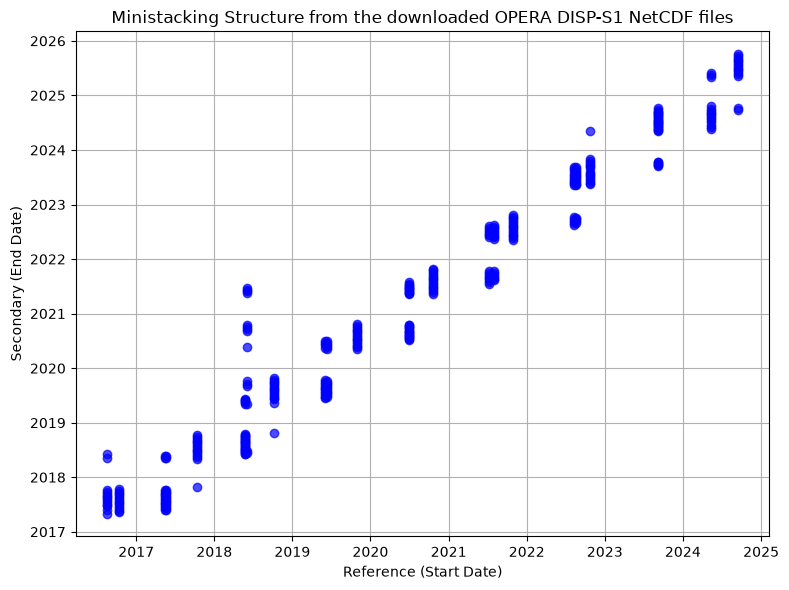

Files information:


,project,level,product,mode,frame_id,polarizarion,start_date,end_date,version,production_date,path,date12,date1,date2
0,OPERA,L3,DISP-S1,IW,F40860,VV,2016-08-18 04:26:54,2017-05-03 04:26:12,v1.0,20250829T165406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160...,20160818_20170503,20160818,20170503
1,OPERA,L3,DISP-S1,IW,F40860,VV,2016-08-18 04:26:54,2017-05-27 04:26:13,v1.0,20250829T165406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160...,20160818_20170527,20160818,20170527
2,OPERA,L3,DISP-S1,IW,F40860,VV,2016-08-18 04:26:54,2017-06-20 04:26:14,v1.0,20250829T165406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160...,20160818_20170620,20160818,20170620
3,OPERA,L3,DISP-S1,IW,F40860,VV,2016-08-18 04:26:54,2017-07-02 04:26:15,v1.0,20250829T165406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160...,20160818_20170702,20160818,20170702
4,OPERA,L3,DISP-S1,IW,F40860,VV,2016-08-18 04:26:54,2017-07-14 04:26:16,v1.0,20250829T165406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160...,20160818_20170714,20160818,20170714
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
366,OPERA,L3,DISP-S1,IW,F31231,VV,2024-09-14 17:26:18,2025-08-16 17:26:08,v1.0,20260310T014531Z,subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20240...,20240914_20250816,20240914,20250816
367,OPERA,L3,DISP-S1,IW,F31231,VV,2024-09-14 17:26:18,2025-08-28 17:26:08,v1.0,20260310T014531Z,subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20240...,20240914_20250828,20240914,20250828
368,OPERA,L3,DISP-S1,IW,F31231,VV,2024-09-14 17:26:18,2025-09-09 17:26:09,v1.0,20260310T014531Z,subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20240...,20240914_20250909,20240914,20250909
369,OPERA,L3,DISP-S1,IW,F31231,VV,2024-09-14 17:26:18,2025-09-21 17:26:09,v1.0,20260310T014531Z,subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20240...,20240914_20250921,20240914,20250921


In [7]:
# Load displacement info from the directory
nc_dir = "subset-ncs"
disp_df = product.get_disp_info(nc_dir)

# Group by version
versions = {}
for version in disp_df["version"].unique():
    df = disp_df[disp_df["version"] == version].copy()
    versions[version] = df
    print(f"{version}, size: {df.shape[0]}")

# Plot Date1 vs Date2 for each version
for version, df in versions.items():
    df["date1"] = pd.to_datetime(df["date1"], format="%Y%m%d")
    df["date2"] = pd.to_datetime(df["date2"], format="%Y%m%d")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(df["date1"], df["date2"], alpha=0.7, marker="o", color="b")
    ax.set_xlabel("Reference (Start Date)")
    ax.set_ylabel("Secondary (End Date)")
    ax.set_title("Ministacking Structure from the downloaded OPERA DISP-S1 NetCDF files")
    ax.grid(True)
    plt.tight_layout()
    plt.show()
    
print('Files information:')
disp_df

## Optimized timeline creation and filtering using data across multiple frames

This cell creates a timeline within a dataframe containing the best records from user-defined time ranges, measured in interyears.
The resulting candidacy of whether or not we work with a record is clearly marked with a colored square and an appropriate label.

In [8]:
'''
The coding logic of this cell was written with the assistance of Google Gemini for learning purposes, being reviewed and refined by the human author(s).
The integrity of the pseudocode and thought process related to data extraction has been kept intact before, during, and after this assistance.
'''

# Converts dates to datetime objects for the whole pool at once
disp_df['start_dt'] = pd.to_datetime(disp_df['start_date'])
disp_df['end_dt'] = pd.to_datetime(disp_df['end_date'])


# ==========================================================
# STEP 1: CREATE A TIMELINE W/ RECORD OPTIMIZATION
# ==========================================================
print("Extracting optimal interannual timeline...")

# Defines the exact yearly transitions you want to find
# (Not written by simple start and end years in order to give the user some flexibility with time gaps)
interyears = [(2016, 2017), (2017, 2018), (2018, 2019), (2019, 2020), (2020, 2021),
              (2021, 2022), (2022, 2023), (2023, 2024), (2024, 2025)]
timeline_pairs = []

for year_start, year_end in interyears:
    # Filters for the exact years AND the same calendar month
    mask = (
        (disp_df['start_dt'].dt.year == year_start) & 
        (disp_df['end_dt'].dt.year == year_end) & 
        (disp_df['start_dt'].dt.month == disp_df['end_dt'].dt.month)
    )
    
    # Isolates the candidates for this specific year transition
    year_candidates = disp_df[mask].reset_index(drop=True)
    
    if len(year_candidates) > 0:
        # Extracts the day of the year (DOY: 1-365)
        start_doy = year_candidates['start_dt'].dt.dayofyear
        end_doy = year_candidates['end_dt'].dt.dayofyear

        # Creates masks for our two seasonal tiers
        # True if start OR end falls within the inclusive range
        check1_mask = ((start_doy >= 180) & (start_doy <= 220)) | ((end_doy >= 180) & (end_doy <= 220))
        check2_mask = ((start_doy >= 160) & (start_doy <= 240)) | ((end_doy >= 160) & (end_doy <= 240))

        # Quick note that a one-day discrepancy caused by a leap year is negligible to us

        # Nested IF structure to determine which pool of records we use
        if check1_mask.any():
            target_df = year_candidates[check1_mask].reset_index(drop=True)
            tier_used = "🟩 Usable! (Best DOY of 180-220)" # Least chance for heavy snowfall
        elif check2_mask.any():
            target_df = year_candidates[check2_mask].reset_index(drop=True)
            tier_used = "🟨 Usuable...? (Expanded DOY of 160-240)" # May or may not be okay (Proceed w/ caution)
        else:
            target_df = year_candidates.copy()
            tier_used = "🟥 Not Usable. (Outside our DOY ranges)" # Results may be shaky at best (Don't proceed)

        # Now we minimize the day gap on whatever subset was sorted and selected above
        t_start = pd.to_datetime(target_df['start_date'])
        t_end = pd.to_datetime(target_df['end_date'])
        
        # Calculates row-by-row day gaps and isolates the row index with the minimum gap
        min_day_idx = (t_end - t_start).abs().idxmin()
        
        # Extracts the absolute best record for this year transition
        best_entry = target_df.loc[[min_day_idx]].copy()
        
        # Cleans up the temporary datetime columns before saving
        best_entry = best_entry.drop(columns=['start_dt', 'end_dt'])
        
        timeline_pairs.append(best_entry)
        
        # Prints a nice summary of what record was chosen for the specific interyear
        print(f"🎯 {year_start}-{year_end} Best Pair: {best_entry['start_date'].iloc[0]} to {best_entry['end_date'].iloc[0]} "
              f"(Frame {best_entry['frame_id'].iloc[0]}, {tier_used})")
    else:
        print(f"❌ No valid records found in the pool for transition {year_start} to {year_end}")

print("\n==================================================\n")

# ==========================================
# STEP 2: ASSEMBLE FINAL DATAFRAME
# ==========================================
if timeline_pairs:
    timeline_df_search = pd.concat(timeline_pairs, ignore_index=True)
    
    # Shuffle frame_id to the front for readability
    cols = ['frame_id'] + [c for c in timeline_df_search.columns if c != 'frame_id']
    timeline_df_search = timeline_df_search[cols]
    
    display(timeline_df_search)
else:
    print("Could not build the timeline. No valid pairs found.")

print(f"✅ Timeline created with {len(timeline_df_search)} total displacement records.\n")

Extracting optimal interannual timeline...
🎯 2016-2017 Best Pair: 2016-08-18 04:26:54 to 2017-08-07 04:26:17 (Frame F40860, 🟩 Usable! (Best DOY of 180-220))
🎯 2017-2018 Best Pair: 2017-05-16 17:42:12 to 2018-05-11 17:42:18 (Frame F23445, 🟥 Not Usable. (Outside our DOY ranges))
🎯 2018-2019 Best Pair: 2018-05-25 17:25:46 to 2019-05-08 17:25:51 (Frame F31231, 🟥 Not Usable. (Outside our DOY ranges))
🎯 2019-2020 Best Pair: 2019-06-11 17:42:25 to 2020-06-29 17:42:33 (Frame F23445, 🟩 Usable! (Best DOY of 180-220))
🎯 2020-2021 Best Pair: 2020-06-29 17:42:33 to 2021-06-12 17:42:38 (Frame F23445, 🟩 Usable! (Best DOY of 180-220))
🎯 2021-2022 Best Pair: 2021-07-30 17:42:41 to 2022-07-01 17:42:45 (Frame F23445, 🟩 Usable! (Best DOY of 180-220))
🎯 2022-2023 Best Pair: 2022-08-18 17:42:48 to 2023-08-01 17:42:52 (Frame F23445, 🟩 Usable! (Best DOY of 180-220))
🎯 2023-2024 Best Pair: 2023-09-08 17:26:22 to 2024-09-02 17:26:17 (Frame F31231, 🟥 Not Usable. (Outside our DOY ranges))
🎯 2024-2025 Best Pair: 2

,frame_id,project,level,product,mode,polarizarion,start_date,end_date,version,production_date,path,date12,date1,date2
0,F40860,OPERA,L3,DISP-S1,IW,VV,2016-08-18 04:26:54,2017-08-07 04:26:17,v1.0,20250829T165406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F40860_VV_20160...,20160818_20170807,20160818,20170807
1,F23445,OPERA,L3,DISP-S1,IW,VV,2017-05-16 17:42:12,2018-05-11 17:42:18,v1.0,20260225T021618Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20170...,20170516_20180511,20170516,20180511
2,F31231,OPERA,L3,DISP-S1,IW,VV,2018-05-25 17:25:46,2019-05-08 17:25:51,v1.0,20250829T222334Z,subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20180...,20180525_20190508,20180525,20190508
3,F23445,OPERA,L3,DISP-S1,IW,VV,2019-06-11 17:42:25,2020-06-29 17:42:33,v1.0,20250830T032406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20190...,20190611_20200629,20190611,20200629
4,F23445,OPERA,L3,DISP-S1,IW,VV,2020-06-29 17:42:33,2021-06-12 17:42:38,v1.0,20250830T095150Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20200...,20200629_20210612,20200629,20210612
5,F23445,OPERA,L3,DISP-S1,IW,VV,2021-07-30 17:42:41,2022-07-01 17:42:45,v1.0,20250830T161015Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20210...,20210730_20220701,20210730,20220701
6,F23445,OPERA,L3,DISP-S1,IW,VV,2022-08-18 17:42:48,2023-08-01 17:42:52,v1.0,20250830T202045Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20220...,20220818_20230801,20220818,20230801
7,F31231,OPERA,L3,DISP-S1,IW,VV,2023-09-08 17:26:22,2024-09-02 17:26:17,v1.0,20250831T160907Z,subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20230...,20230908_20240902,20230908,20240902
8,F31231,OPERA,L3,DISP-S1,IW,VV,2024-09-14 17:26:18,2025-09-09 17:26:09,v1.0,20260310T014531Z,subset-ncs/OPERA_L3_DISP-S1_IW_F31231_VV_20240...,20240914_20250909,20240914,20250909


✅ Timeline created with 9 total displacement records.



## Cleaning up the data

We need to filter out any overtly bad data (indicated by the red squares) in our newly created timeline dataframe in order to not contaminate the rest of the results that will end up going in our master stack.

In [10]:
timeline_df_search['start_date'] = pd.to_datetime(timeline_df_search['start_date'])
timeline_df_search['end_date'] = pd.to_datetime(timeline_df_search['end_date'])

start_doy = timeline_df_search['start_date'].dt.dayofyear
end_doy = timeline_df_search['end_date'].dt.dayofyear

target_min = 160
target_max = 240

# Checks if both the start and end dates fall inside the DOY window
mask = (start_doy >= target_min) & (start_doy <= target_max) & \
       (end_doy >= target_min) & (end_doy <= target_max)

timeline_df = timeline_df_search[mask].reset_index(drop=True)

# There is currently a bug where because earlier records don't have the same map projections as the later records,
# the colormap readings are mostly hazy/blurry due to the current stacking process overlapping these pixels of- 
# differing orientations. A possible fix would potentially involve forcing all records to use the same projection,
# but I have been unsuccessful in accomplishing this without causing the data to completely empty itself when stacking (which leaves nothing to plot).
#
#       - As such, the current workaround is to only use interyears that have the same projection.
#

timeline_df = timeline_df[1:] # When debugging, comment this line out to add back the record in this example with a different projection.

print(f"Retained {len(timeline_df)} out of {len(timeline_df_search)} records to use for the master stack.")
timeline_df

Retained 4 out of 9 records to use for the master stack.


,frame_id,project,level,product,mode,polarizarion,start_date,end_date,version,production_date,path,date12,date1,date2
1,F23445,OPERA,L3,DISP-S1,IW,VV,2019-06-11 17:42:25,2020-06-29 17:42:33,v1.0,20250830T032406Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20190...,20190611_20200629,20190611,20200629
2,F23445,OPERA,L3,DISP-S1,IW,VV,2020-06-29 17:42:33,2021-06-12 17:42:38,v1.0,20250830T095150Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20200...,20200629_20210612,20200629,20210612
3,F23445,OPERA,L3,DISP-S1,IW,VV,2021-07-30 17:42:41,2022-07-01 17:42:45,v1.0,20250830T161015Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20210...,20210730_20220701,20210730,20220701
4,F23445,OPERA,L3,DISP-S1,IW,VV,2022-08-18 17:42:48,2023-08-01 17:42:52,v1.0,20250830T202045Z,subset-ncs/OPERA_L3_DISP-S1_IW_F23445_VV_20220...,20220818_20230801,20220818,20230801


At this point, any filtered-out data takes up a big amount of space in the storage. That data will not be brought up again on any future step in this notebook, so if you wish to delete any unused files, it would be safe to do so.

The future steps in this notebook will work regardless if you clean up space or not.

## Visualize the displacement contained in one file

What you'll see on the following maps is the displacement value for the first file in the stack, meaning it shows the cumulative deformation between the start date and the end date *(reference date to secondary date)*.

- The left panel shows the displacement in **UTM coordinates**, which maintains the original projection of the dataset.
- The right panel shows the same displacement data but **reprojected to geographic coordinates (EPSG:4326)**, using latitude and longitude.

- Colors represent motion in the satellite's line-of-sight (LOS) direction  
  - **Red** indicates motion **away** from the satellite  
  - **Blue** indicates motion **toward** the satellite

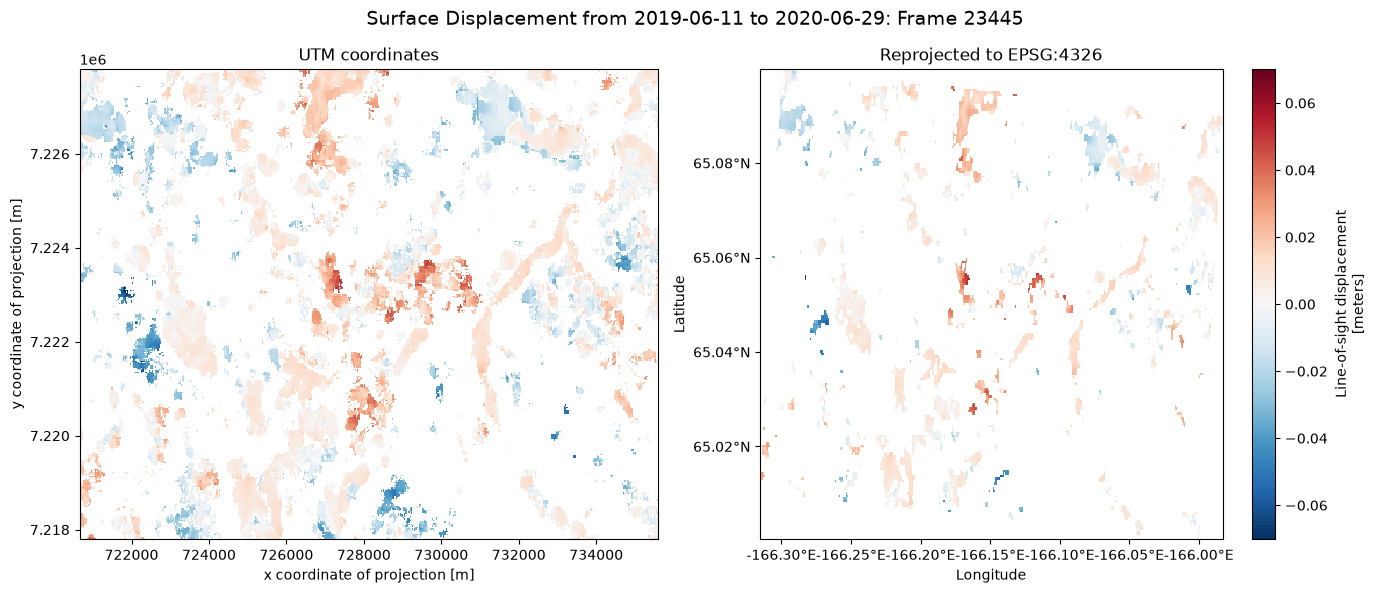

In [11]:
# Load resulting file
row = timeline_df.iloc[0]
ds = xr.open_dataset(row.path, chunks={"time": 1})

frame = row.loc['frame_id'][1:] # Removes the 'F' character at the beginning for simplicity

# Format dates
d1 = pd.to_datetime(row.date1, format="%Y%m%d").date()
d2 = pd.to_datetime(row.date2, format="%Y%m%d").date()
title = f"Surface Displacement from {d1} to {d2}: Frame {frame}"

# Mask displacement
da = ds.where(ds.recommended_mask == 1).isel(time=-1).displacement

# Reproject to lat/lon
da.rio.write_crs(pyproj.CRS(ds.spatial_ref.attrs['crs_wkt']).to_epsg(), inplace=True)
da.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=True)
da_4326 = da.rio.reproject("EPSG:4326", resampling=rasterio.enums.Resampling.bilinear)

# Plot side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left: UTM
da.plot.imshow(ax=ax1, cmap="RdBu_r", add_colorbar=False)
ax1.set_title("UTM coordinates")

# Right: Lat/Lon
im = da_4326.plot.imshow(ax=ax2, cmap="RdBu_r", add_colorbar=True)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}°E"))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:.2f}°N"))
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
ax2.set_title("Reprojected to EPSG:4326")

# Shared title and layout
fig.suptitle(title, fontsize=14)
plt.tight_layout()
plt.show()


## Stacking the OPERA DISP-S1 Files

The `stack_prod` object is an `xarray.Dataset` that represents the full stack of DISP-S1 data loaded from the downloaded DISP-S1 NetCDF files.

As shown below, the dataset includes:
- **Coordinates**: spatial (x, y) and temporal (time) axes
- **Data variables**: multiple layers beyond just displacement
- **Attributes**: metadata describing the product version, projection, mission, and contact info

While the **`displacement`** variable is the main product of interest (cumulative surface motion in the LOS from the reference date), DISP-S1 products also include a variety of **supporting layers**.

<font color="red">📌 A more detailed explanation of each layer will be provided later in the notebook.</font>


In [12]:
# CURRENT VERSION (no reproj_match) - this only works as intended without the first record

from pathlib import Path

# for "xr.open_mfdataset",
# xarray calls this function on every individual file before attempting to combine them
def mask_4326(ds):
    # Extracts the native EPSG from spatial_ref attributes
    native_wkt = ds.spatial_ref.attrs.get('crs_wkt') or ds.spatial_ref.attrs.get('spatial_ref')
    epsg = pyproj.CRS(native_wkt).to_epsg()
    
    # Main preprocessing commands
    ds['displacement'] = ds['displacement'].where((ds['recommended_mask'] == 1) 
                                                  #& (ds['water_mask'] == 1)
                                                  )
    ds.rio.write_crs(epsg, inplace=True)
    ds.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=True)
    
    # Reproject to EPSG:4326 (WGS84 lat/lon)
    ds_reproj = ds.rio.reproject("EPSG:4326", resampling=rasterio.enums.Resampling.bilinear)
    
    return ds_reproj

data_dir = Path('/sciclone/home/dfbunich/subset-ncs')

timeline_files = set(Path(p).name for p in timeline_df['path'])
target_files = [f for f in sorted(data_dir.glob('OPERA_L3_DISP-S1_*.nc')) if f.name in timeline_files]

print(f"Attempting open_mfdataset across {len(target_files)} files with preprocess reprojection...")

try:
    # "Open multi-file dataset" with dask chunking and custom preprocessing
    stack_prod = xr.open_mfdataset(
        target_files,
        concat_dim='time',
        combine='nested',
        data_vars='all',
        preprocess=mask_4326,
        chunks={'time': 1, 'x': 512, 'y': 512},
        parallel=True
    )
    
    # Assigns date coordinates from timeline_df to the time dimension
    #   (I had to attach something, and the start dates made more sense.
    #    Hopefully this means the end dates are accessible, too.
    #    Maybe it doesn't matter.)
    stack_prod = stack_prod.assign_coords(time=timeline_df['start_date'].values)

    print("✅ xr.open_mfdataset built our geocube:")
    print(stack_prod)

except Exception as e:
    print("\n❌ Something went wrong, reason down below:")
    print(e)

Attempting open_mfdataset across 4 files with preprocess reprojection...
✅ xr.open_mfdataset built our geocube:
<xarray.Dataset> Size: 23MB
Dimensions:                         (time: 4, y: 189, x: 631)
Coordinates:
  * time                            (time) datetime64[ns] 32B 2019-06-11T17:4...
  * y                               (y) float64 2kB 65.1 65.1 65.1 ... 65.0 65.0
  * x                               (x) float64 5kB -166.3 -166.3 ... -166.0
    spatial_ref                     int64 8B 0
Data variables:
    reference_time                  (time) datetime64[ns] 32B dask.array<chunksize=(1,), meta=np.ndarray>
    displacement                    (time, y, x) float64 4MB nan nan ... nan nan
    short_wavelength_displacement   (time, y, x) float32 2MB nan nan ... nan nan
    recommended_mask                (time, y, x) float32 2MB nan nan ... nan nan
    connected_component_labels      (time, y, x) float32 2MB nan nan ... nan nan
    temporal_coherence              (time, y, x) floa

In [78]:
# TRIAL-AND-ERROR VERSION (with reproj_match)

data_dir = Path('/sciclone/home/dfbunich/subset-ncs')

timeline_files = set(Path(p).name for p in timeline_df['path'])
target_files = [f for f in sorted(data_dir.glob('OPERA_L3_DISP-S1_*.nc')) if f.name in timeline_files]

# Establishing the file path to a master grid that forcefully reprojects and aligns everything to
template_path = target_files[-1]
ds_templ = xr.open_dataset(template_path)

# Extracting the native CRS and setting dimensions
native_wkt = ds_templ.spatial_ref.attrs.get('crs_wkt') or ds_templ.spatial_ref.attrs.get('spatial_ref')
epsg_templ = pyproj.CRS(native_wkt).to_epsg()
ds_templ.rio.write_crs(epsg_templ, inplace=True)
ds_templ.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=True)

master_grid = ds_templ.rio.reproject("EPSG:4326")

# for "xr.open_mfdataset",
# xarray calls this function on every individual file before attempting to combine them
def apply_rec_mask(ds):
    native_wkt = ds.spatial_ref.attrs.get('crs_wkt') or ds.spatial_ref.attrs.get('spatial_ref')
    epsg = pyproj.CRS(native_wkt).to_epsg()

    # Main preprocessing commands
    ds['displacement'] = ds['displacement'].where((ds['recommended_mask'] == 1) & (ds['water_mask'] == 1))
    ds.rio.write_crs(epsg, inplace=True)
    ds.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=True)

    # The command that should hypothetically help here
    ds_align = ds.rio.reproject_match(master_grid, resampling=rasterio.enums.Resampling.bilinear)
    
    return ds_align

print(f"Attempting open_mfdataset across {len(target_files)} files with preprocess reprojection...")

try:
    # "Open multi-file dataset" with dask chunking and custom preprocessing
    stack_prod = xr.open_mfdataset(
        target_files,
        concat_dim='time',
        combine='nested',
        data_vars='all',
        preprocess=apply_rec_mask,
        parallel=True
    )
    
    # Assigns date coordinates from timeline_df to the time dimension
    stack_prod = stack_prod.assign_coords(time=timeline_df['start_date'].values)

    stack_prod = stack_prod.chunk({'time': 1, 'x': 512, 'y': 512})

    print("✅ xr.open_mfdataset built our geocube:")
    print(stack_prod)

except Exception as e:
    print("\n❌ Something went wrong, reason down below:")
    print(e)

Attempting open_mfdataset across 4 files with preprocess reprojection...
✅ xr.open_mfdataset built our geocube:
<xarray.Dataset> Size: 23MB
Dimensions:                         (time: 4, y: 189, x: 631)
Coordinates:
  * time                            (time) datetime64[ns] 32B 2019-06-11T17:4...
  * y                               (y) float64 2kB 65.1 65.1 65.1 ... 65.0 65.0
  * x                               (x) float64 5kB -166.3 -166.3 ... -166.0
    spatial_ref                     int64 8B 0
Data variables:
    reference_time                  (time) datetime64[ns] 32B dask.array<chunksize=(1,), meta=np.ndarray>
    displacement                    (time, y, x) float64 4MB dask.array<chunksize=(1, 189, 512), meta=np.ndarray>
    short_wavelength_displacement   (time, y, x) float32 2MB dask.array<chunksize=(1, 189, 512), meta=np.ndarray>
    recommended_mask                (time, y, x) float32 2MB dask.array<chunksize=(1, 189, 512), meta=np.ndarray>
    connected_component_labels     

In [14]:
# Debugging for figure display issue: Is stack_prod completely empty?
#                                     - If yes, rework the code.
valid_count = np.count_nonzero(~np.isnan(stack_prod['displacement'].values))
print(f"Total non-NaN pixels in stack: {valid_count}  (If non-NaN count >0, stack is not empty)")
print(f"Dimension of stack is: {len(stack_prod.x)} * {len(stack_prod.y)} = {len(stack_prod.x)*len(stack_prod.y)}")

Total non-NaN pixels in stack: 83133  (If non-NaN count >0, stack is not empty)
Dimension of stack is: 631 * 189 = 119259


## Selecting a Reference Point for Displacement

InSAR displacement measurements are **relative in both space and time**. They show movement **with respect to a chosen reference point**.  
To interpret the displacement meaningfully, we need to define a point that is assumed to be:
- Not moving during the observed time period  
- Or located near your area of interest or object, to capture differential motion relative to it

The reference point will serve as the zero-displacement baseline, and all other pixel values in the stack will be computed relative to it.
It means that if this points is noisy or unreliable, every other pixels will be affected.

<font color="red"> Choosing a good reference is important: a stable or nearby point helps isolate the motion you're investigating.</font>

In [15]:
# Lat/lon of the reference point
# (Choose any stable point within your BBOX that makes sense.)
lat, lon = 65.086982, -166.169205

ref_disp = stack_prod.sel(x=lon, y=lat, method='nearest').displacement

# Subtract reference
stack_prod['displacement'] = stack_prod.displacement - ref_disp

## Visualize Individual & Pixelwise Average Displacement Relative to Reference Point

The following maps in-order show the individual displacement of every record as well as the pixelwise average displacement from the first reference date to the last acquisition date in the stack:
- Colors represent motion in the satellite's line-of-sight (LOS) direction  
  - **Red** indicates motion **away** from the satellite  
  - **Blue** indicates motion **toward** the satellite
- The green dot marks the **reference point**, which has been set to zero displacement
- The values are in **centimeters**, relative to that reference

In [16]:
def get_baseimage_from_bounds(bounds, source, grayscale=False, gamma=None, log=None, zoom='auto'):
    xmin, ymin, xmax, ymax = bounds
    left, right, bottom, top = cx.plotting._reproj_bb(xmin, xmax, ymin, ymax, 'EPSG:4326', "epsg:3857")
    image, extent = cx.tile.bounds2img(left, bottom, right, top, zoom=zoom, source=source, ll=False)
    image, extent = cx.tile.warp_tiles(image, extent, t_crs='EPSG:4326', resampling=rasterio.enums.Resampling.bilinear)
    if grayscale:
        image = rgb2gray(image[:, :, :3])
    if gamma is not None:
        image = exposure.adjust_gamma(image, gamma)
    if log is not None:
        image = exposure.adjust_log(image, log)
    return image, extent

## Individual scenes

The cell below generates plots for all of the individual records in the master stack so we can see exactly what interyears contribute to each trend shown in the final pixelwise averaged figure.

Generating individual interyear figures using data from stack_prod...


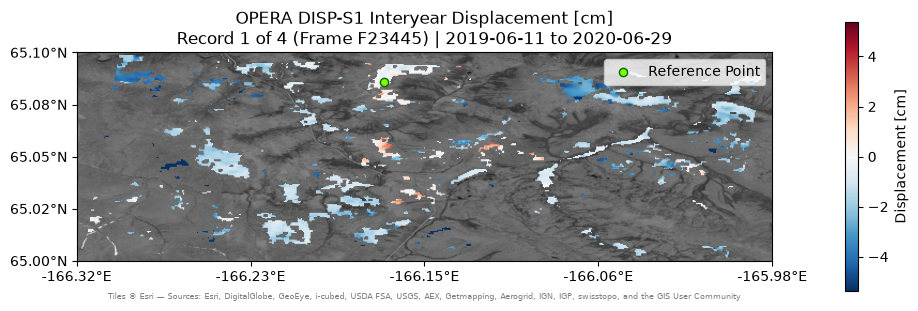

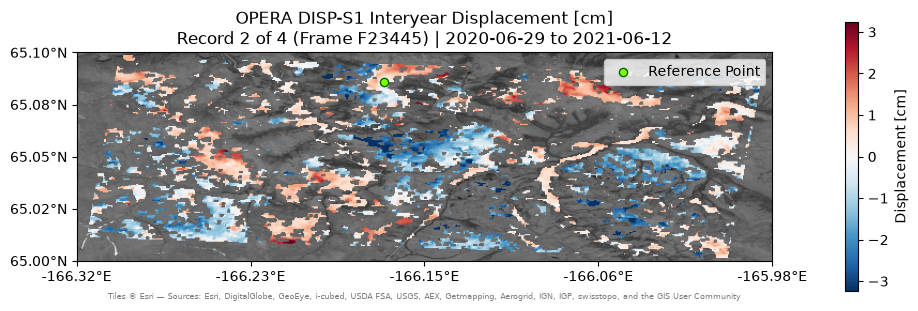

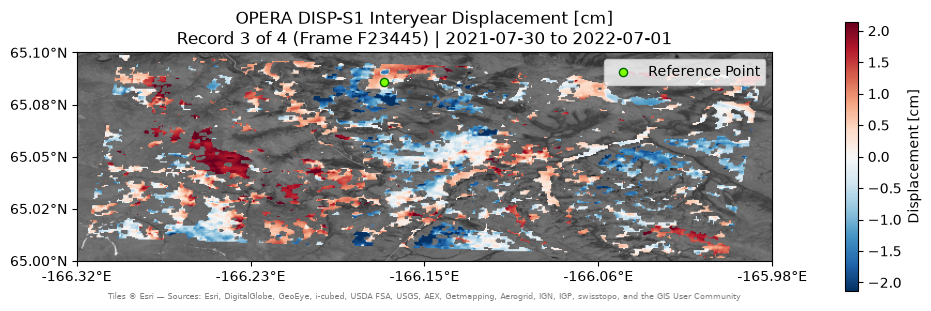

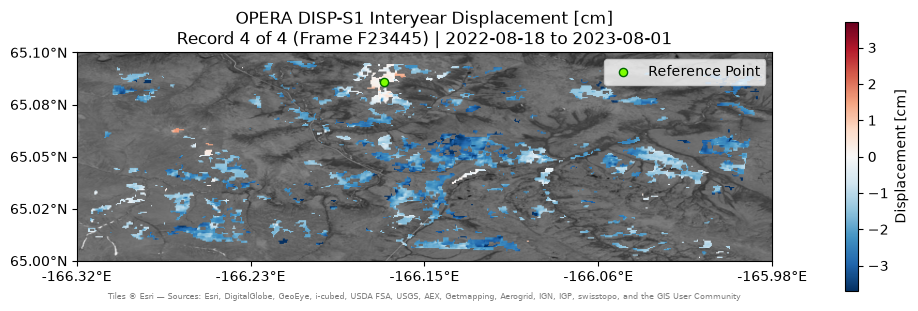

In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

print("Generating individual interyear figures using data from stack_prod...")

raw_bounds = stack_prod.displacement.rio.bounds()
xmin, xmax = sorted([raw_bounds[0], raw_bounds[2]])
ymin, ymax = sorted([raw_bounds[1], raw_bounds[3]])

buffer_fraction = 0.015
x_pad = (xmax - xmin) * buffer_fraction
y_pad = (ymax - ymin) * buffer_fraction

buffered_bounds = [xmin - x_pad, ymin - y_pad, xmax + x_pad, ymax + y_pad]
extent = [buffered_bounds[0], buffered_bounds[2], buffered_bounds[1], buffered_bounds[3]]

# Downloads the basemap
bg, bg_extent = get_baseimage_from_bounds(
    buffered_bounds, 
    source=cx.providers.Esri.WorldImagery, 
    grayscale=True, 
    gamma=0.9
)

for i in range(len(stack_prod.time)):
    # Extracts individual record time slice (convert to cm)
    da_slice = stack_prod.displacement.isel(time=i) * 100
    
    row = timeline_df.iloc[i]
    frame = row.get('frame_id', 'N/A')
    d1 = str(row['start_date'])[:10]
    d2 = str(row['end_date'])[:10]
    
    # Calculates colormap thresholds by chopping off noise at the extremes
    p_low, p_high = np.nanpercentile(da_slice.values, [2, 98])
    vmax = max(abs(p_low), abs(p_high)) if not np.isnan(p_low) else 2.0
    vmin = -vmax

    # Sets up canvas and latitude aspect ratio correction
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])

    # center_lat = (extent[2] + extent[3]) / 2
    # ax.set_aspect(1 / np.cos(np.radians(center_lat)))

    # Displays basemap in figure
    ax.imshow(bg, extent=bg_extent, cmap="gray", origin="upper", zorder=1, alpha=1)

    # Overlays single interyear displacement layer
    im = ax.imshow(
        da_slice.values, 
        extent=[xmin, xmax, ymin, ymax], 
        cmap="RdBu_r", 
        vmin=vmin, 
        vmax=vmax, 
        alpha=1, 
        origin="upper", 
        zorder=2
    )

    # Reference point
    ax.scatter(lon, lat, color="chartreuse", edgecolor="darkgreen", s=35, label="Reference Point", zorder=3)

    # Formatting & Colorbar
    cbar = plt.colorbar(im, ax=ax, shrink=0.35, pad=0.08)
    cbar.set_label("Displacement [cm]")

    ax.set_xticks(np.linspace(extent[0], extent[1], 5))
    ax.set_yticks(np.linspace(extent[2], extent[3], 5))
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}°E"))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:.2f}°N"))
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

    ax.annotate(
        "Tiles © Esri — Sources: Esri, DigitalGlobe, GeoEye, i-cubed, USDA FSA, USGS, AEX, "
        "Getmapping, Aerogrid, IGN, IGP, swisstopo, and the GIS User Community",
        xy=(0.5, -0.15), xycoords='axes fraction', ha='center', va='top', fontsize=6, color='gray'
    )

    ax.legend()
    ax.set_title(f"OPERA DISP-S1 Interyear Displacement [cm]\nRecord {i+1} of {len(timeline_df)} (Frame {frame}) | {d1} to {d2}")
    
    plt.tight_layout()
    plt.show()

## Pixelwise average across all scenes

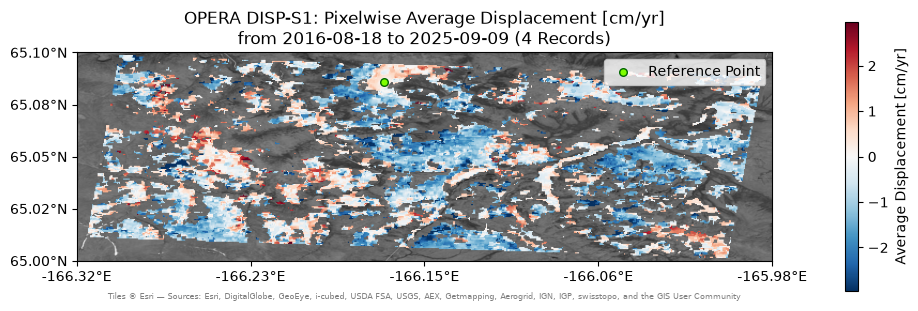

In [18]:
# skipna=True ignores masked NaNs, averaging the value of each pixel only with the valid observations.
#   This is a good compromise since we want as much data as possible within the time search range,
#   but we don't want to analyze the bad records of pixels, anyway.
da_all = stack_prod.displacement * 100  # Convert to cm
da_mean = da_all.mean(dim='time', skipna=True)

# Pulls the boundary data for padding calcs
raw_bounds = da_mean.rio.bounds()  # returns (left, bottom, right, top) or similar depending on axis order

# Locates xmin < xmax and ymin < ymax regardless of array coordinate orientation
xmin, xmax = sorted([raw_bounds[0], raw_bounds[2]])
ymin, ymax = sorted([raw_bounds[1], raw_bounds[3]])

buffer_fraction = 0.015 # The thickness multiplier of the padding scale
x_pad = (xmax - xmin) * buffer_fraction
y_pad = (ymax - ymin) * buffer_fraction

# Construct buffered bounds explicitly ensuring min < max
buffered_bounds = [
    xmin - x_pad,  # xmin / left padding
    ymin - y_pad,  # ymin / bottom padding
    xmax + x_pad,  # xmax / right padding
    ymax + y_pad   # ymax / top padding
]

# Matplotlib extent: [left, right, bottom, top]
extent = [buffered_bounds[0], buffered_bounds[2], buffered_bounds[1], buffered_bounds[3]]

# Normalizes colormap thresholds
v = np.nanpercentile(da_mean.values, [2.25, 97.75])
vmax = max(abs(v[0]), abs(v[1])) if not np.isnan(v).all() else 0.5
vmin = -vmax

# Sets up the figure canvas
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

# center_lat = (extent[2] + extent[3]) / 2
# ax.set_aspect(1 / np.cos(np.radians(center_lat)))

# Downloads and displays basemap
bg, bg_extent = get_baseimage_from_bounds(
    buffered_bounds, 
    source=cx.providers.Esri.WorldImagery, 
    grayscale=True, 
    gamma=0.9
)
ax.imshow(bg, extent=bg_extent, cmap="gist_gray", origin="upper", alpha=1, zorder=1)

# Overlays the pixelwise average displacement layer
im = ax.imshow(
    da_mean.values, 
    extent=[xmin, xmax, ymin, ymax], 
    cmap=plt.get_cmap("RdBu_r"), 
    vmin=vmin, 
    vmax=vmax, 
    alpha=1, 
    origin="upper", 
    zorder=2
)

# Reference point
ax.scatter(lon, lat, color="chartreuse", edgecolors="darkgreen", s=30, label="Reference Point", zorder=3)

# Formatting
cbar = plt.colorbar(im, ax=ax, shrink=0.35, pad=0.08)
cbar.set_label("Average Displacement [cm/yr]")

ax.set_xticks(np.linspace(extent[0], extent[1], 5))
ax.set_yticks(np.linspace(extent[2], extent[3], 5))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:.2f}°N"))
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

ax.annotate(
    "Tiles © Esri — Sources: Esri, DigitalGlobe, GeoEye, i-cubed, USDA FSA, USGS, AEX, "
    "Getmapping, Aerogrid, IGN, IGP, swisstopo, and the GIS User Community",
    xy=(0.5, -0.15), xycoords='axes fraction', ha='center', va='top', fontsize=6, color='gray'
)

ax.legend()

# Title reflecting the full date range across all records
d1 = str(timeline_df_search.iloc[0]['start_date'])[0:10]
d2 = str(timeline_df_search.iloc[-1]['end_date'])[0:10]
ax.set_title(f"OPERA DISP-S1: Pixelwise Average Displacement [cm/yr]\nfrom {d1} to {d2} ({len(target_files)} Records)")

plt.tight_layout()
plt.show()

## Comparing the results

Comparing our OPERA displacement calculations with those presented in the 2023 paper, there is only a vaguely positive correlation, judging by how scattered the plot looks. It is worth considering that each dataset's time ranges were very different. Though given that they both cover the same study area, these results are still indicative of a great disparity.

This is further supported by the exceptionally low p-value and R^2 value. The p-value being effectively zero indicates that the result attained in this case study is without a doubt statistically significant. However, the strong noise indicated by the R^2 value of ~4.54% suggests that this result considerably diverges from the paper's findings.

I have also color-coded each point by its temporal coherence value in stack_prod. This is to help streamline any next steps by identifying where exactly the noise may come from. Generally, the more temporally coherent a point is, the more stable the radar was in collecting the data there (less interference, more consistency, etc.).

=== Regression Statistics ===
R-squared: 0.0454
P-value:   0.0000e+00


/local/scr/dfbunich/TMPDIR/ipykernel_652221/1513383611.py:62: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


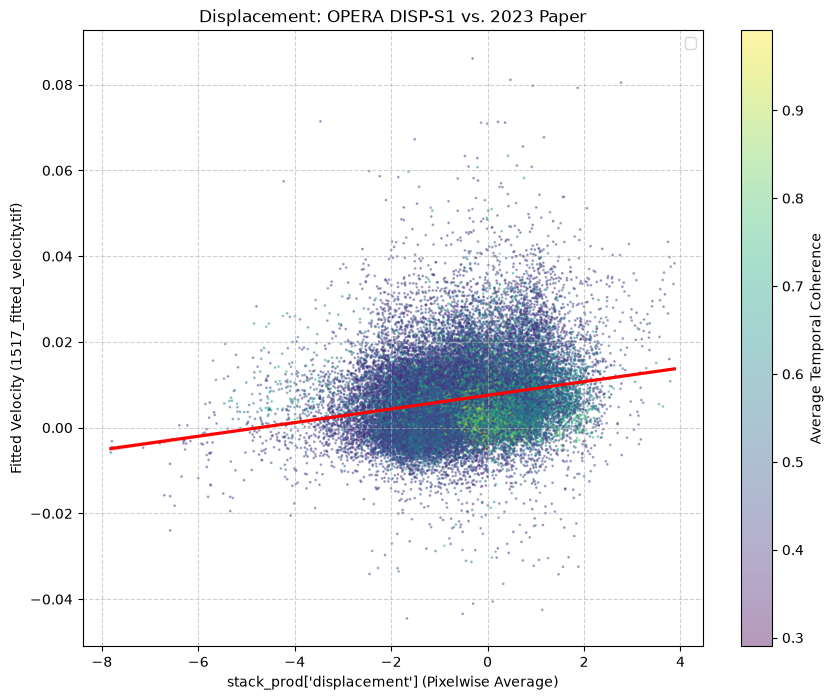

In [32]:
import seaborn as sns
from scipy.stats import linregress

# Calculates the pixelwise average of your displacement data
avg_disp = da_all.mean(dim='time')
avg_disp = avg_disp.rio.write_crs("EPSG:4326")

# Extracts the temporal coherence from the metadata for color-coding 
if 'temporal_coherence' in stack_prod:
    color_data = stack_prod['temporal_coherence'].mean(dim='time')
    cbar_label = "Average Temporal Coherence"

# Reads in the TIFF file and selects Band 1 (velocity data)
external_data = rioxarray.open_rasterio("1517_fitted_velocity.tif").sel(band=1)

# Spatially matches the TIFF raster grid to our displacement grid
external_matched = external_data.rio.reproject_match(avg_disp)

# Flattens the 2D arrays into 1D arrays
x_vals = avg_disp.values.flatten()
y_vals = external_matched.values.flatten()
c_vals = color_data.values.flatten()

# Masks out NoData/NaN values across all three arrays
valid_mask = ~np.isnan(x_vals) & ~np.isnan(y_vals) & ~np.isnan(c_vals)
x_valid = x_vals[valid_mask]
y_valid = y_vals[valid_mask]
c_valid = c_vals[valid_mask]

# Generates the plot
plt.figure(figsize=(10, 8))

# Calculates the regression statistics
slope, intercept, r_value, p_value, std_err = linregress(x_valid, y_valid)
print("=== Regression Statistics ===")
print(f"R-squared: {r_value**2:.4f}")
print(f"P-value:   {p_value:.4e}")
print("=============================")

# Draws all of the points on the plot
# The 'c' parameter applies the temporal coherence variable to the color map
scatter = plt.scatter(x_valid, y_valid, c=c_valid, cmap='viridis', alpha=0.4, s=1)

# Overlays the 95% Confidence Interval regression line using Seaborn
# scatter=False ensures seaborn doesn't try to redraw the millions of points
sns.regplot(
    x=x_valid, 
    y=y_valid, 
    scatter=False, 
    color='red',
    line_kws={'label': 'Linear Regression w/ 95% CI'}
)

# Adds the colorbar to the side of the plot
cbar = plt.colorbar(scatter)
cbar.set_label(cbar_label)

plt.xlabel("stack_prod['displacement'] (Pixelwise Average)")
plt.ylabel("Fitted Velocity (1517_fitted_velocity.tif)")
plt.title("Displacement: OPERA DISP-S1 vs. 2023 Paper")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.show()

_______________________________________

### *Everything after this point is in a mostly experimental/work-in-progress state.*

## Creating a separate high-definition snow mask using Sentinel-2

While the "recommended_mask" variable does take into account some dry snow in filtering out bad pixels, Sentinel-2 is just much more robust than Sentinel-1 at measuring the snowy pixels that we want to exclude within our very snowy region.

In [31]:
from loadRasterSTAC import Sentinel2STAC

mySearchParams = {
    'AOI'             : (-166.3, 65.0, -166.0, 65.1),
    'startDate'       : '2016-07',
    'endDate'         : '2025-12',
    'cloudCovMaxPct'  : '40',
    'nanPxlMaxPct'    : '40'}

search = Sentinel2STAC(mySearchParams)

search.searchParams

{'AOI': (-166.3, 65.0, -166.0, 65.1),
 'startDate': '2016-07',
 'endDate': '2025-12',
 'cloudCovMaxPct': '40',
 'nanPxlMaxPct': '40',
 'AOIGeom': <POLYGON ((-166 65, -166 65.1, -166.3 65.1, -166.3 65, -166 65))>}

In [32]:
ndsi=search.doStackSTAC(bands=['ndsi'],
                      filterObs=False,
                   epsg=4326)['ndsi']

ndsi

<xarray.DataArray 'ndsi' (time: 433, lat: 3054, lon: 2003)> Size: 21GB
dask.array<concatenate, shape=(433, 3054, 2003), dtype=float64, chunksize=(1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 3kB 2017-02-05T22:37:14.461000 ... 2025-...
    dayOfYear  (time) int64 3kB 36 39 42 46 49 52 66 ... 279 294 300 302 312 319
  * lat        (lat) float64 24kB 65.1 65.1 65.1 65.1 ... 65.0 65.0 65.0 65.0
  * lon        (lon) float64 16kB -166.3 -166.3 -166.3 ... -166.0 -166.0 -166.0
    epsg       int64 8B 4326

### Demonstration of what a time slice of the NDSI looks like for our region

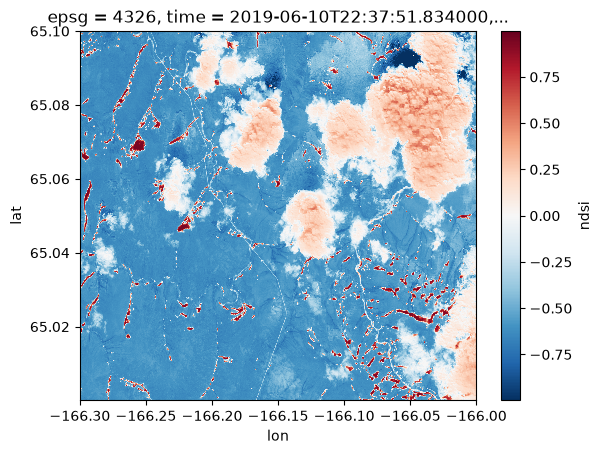

In [20]:
ndsi.sel(time='2019-06-10').plot()

plt.show()  

In [107]:
stack_prod

<xarray.Dataset> Size: 23MB
Dimensions:                         (time: 4, y: 189, x: 631)
Coordinates:
  * time                            (time) datetime64[ns] 32B 2019-06-11T17:4...
  * y                               (y) float64 2kB 65.1 65.1 65.1 ... 65.0 65.0
  * x                               (x) float64 5kB -166.3 -166.3 ... -166.0
    spatial_ref                     int64 8B 0
Data variables:
    reference_time                  (time) datetime64[ns] 32B dask.array<chunksize=(1,), meta=np.ndarray>
    displacement                    (time, y, x) float64 4MB nan nan ... nan nan
    short_wavelength_displacement   (time, y, x) float32 2MB nan nan ... nan nan
    recommended_mask                (time, y, x) float32 2MB nan nan ... nan nan
    connected_component_labels      (time, y, x) float32 2MB nan nan ... nan nan
    temporal_coherence              (time, y, x) float32 2MB nan nan ... nan nan
    estimated_phase_quality         (time, y, x) float32 2MB nan nan ... nan nan
    persistent_scatterer_mask       (time, y, x) float32 2MB nan nan ... nan nan
    shp_counts                      (time, y, x) float32 2MB nan nan ... nan nan
    water_mask                      (time, y, x) float32 2MB nan nan ... nan nan
    phase_similarity                (time, y, x) float32 2MB nan nan ... nan nan
    timeseries_inversion_residuals  (time, y, x) float32 2MB nan nan ... nan nan
Attributes:
    Conventions:         CF-1.8
    contact:             opera-sds-ops@jpl.nasa.gov
    institution:         NASA JPL
    mission_name:        OPERA
    reference_document:  JPL D-108765
    title:               OPERA_L3_DISP-S1 Product

Below is where we attempt to create the mask and apply it to our data.

In [33]:
# Renames 'lon'/'lat' to 'x'/'y' so rioxarray natively understands the spatial grid
ndsi = ndsi.rename({"lon": "x", "lat": "y"})

# Ensures EPSG:4326 is explicitly registered in rioxarray's metadata
epsg = 'EPSG:4326'
if ndsi.rio.crs is None:
    ndsi = ndsi.rio.write_crs(epsg)

# [Spatial Downsampling]
# We will use 'average' resampling to aggregate the 10-20m Sentinel-2 pixels 
# into the coarser OPERA (Sentinel-1) pixel footprint, rather than just grabbing one random pixel.
ndsi_grid = ndsi.rio.reproject_match(
    stack_prod, 
    resampling=rasterio.enums.Resampling.average
)

# Forces both time axes to standard timezone-naive datetime64[ns]
stack_prod['time'] = stack_prod['time'].astype('datetime64[ns]')
ndsi_grid['time'] = ndsi_grid['time'].astype('datetime64[ns]')

# [Temporal Matching (+/- 5 Days)]
# .reindex() aligns the NDSI time series to the stack_prod time series.
# 'tolerance="5D"' makes it only grab NDSI dates within 5 days of the OPERA date.
#   - If no Sentinel-2 date exists within 5 days, it fills that time slice with NaNs.
ndsi_matched = ndsi_grid.reindex(
    time=stack_prod.time, 
    method='nearest', 
    tolerance='5D'
)

# [Mask Creation & Case Handling]
# ========================================================
# Based on my understanding of the NDSI value scale:
#
#   *  -1 < x < 0:  Very certain this pixel doesn't have snow
#                   * Water body, urban area, bare ground
#   *  0 < x < 0.4: Uncertain of heavy snow
#                   * Thin snow and/or snowy patch
#   *  0.4 < x < 1: Fairly certain this pixel DOES have snow
#                   * Evidence of thick snow
#
#      We want values less than around 0.4
#
# ========================================================
# NDSI < 0.4 means snow-free
# 'ndsi_matched.isnull()' means we don't accidentally mask out valid OPERA data 
# simply because it was too cloudy for Sentinel-2 or outside the 5-day window.
snow_free_mask = (ndsi_matched < 0.4) | ndsi_matched.isnull()

# .where() keeps data where the mask is True, and sets the rest to NaN.
stack_prod['displacement'] = stack_prod['displacement'].where(snow_free_mask)

# Diagnostics
valid_ndsi = int(ndsi_matched.notnull().sum())
dropped_pxls = int((~snow_free_mask).sum())
print(f"Pixels with valid Sentinel-2 data: {valid_ndsi}")
print(f"Pixels successfully masked (dropped) due to snow: {dropped_pxls}")

Pixels with valid Sentinel-2 data: 0
Pixels successfully masked (dropped) due to snow: 0


At this point, we would run the pixelwise averaging code again to see if anything changed. (Currently nothing due to incomplete code)

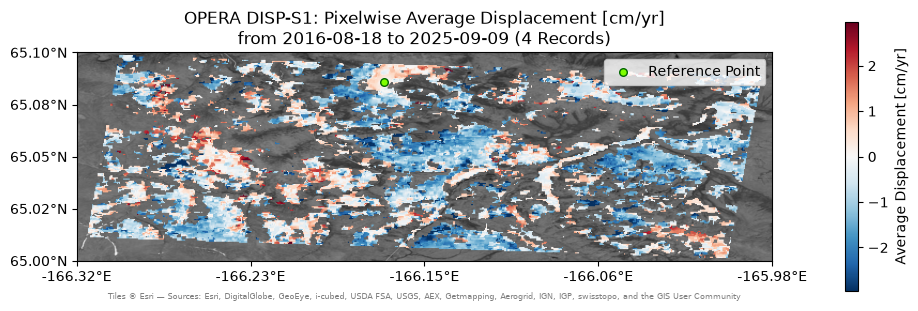

In [34]:
# skipna=True ignores masked NaNs, averaging the value of each pixel only with the valid observations.
#   This is a good compromise since we want as much data as possible within the time search range,
#   but we don't want to analyze the bad records of pixels, anyway.
da_all = stack_prod.displacement * 100  # Convert to cm
da_mean = da_all.mean(dim='time', skipna=True)

# Pulls the boundary data for padding calcs
raw_bounds = da_mean.rio.bounds()  # returns (left, bottom, right, top) or similar depending on axis order

# Locates xmin < xmax and ymin < ymax regardless of array coordinate orientation
xmin, xmax = sorted([raw_bounds[0], raw_bounds[2]])
ymin, ymax = sorted([raw_bounds[1], raw_bounds[3]])

buffer_fraction = 0.015 # The thickness multiplier of the padding scale
x_pad = (xmax - xmin) * buffer_fraction
y_pad = (ymax - ymin) * buffer_fraction

# Construct buffered bounds explicitly ensuring min < max
buffered_bounds = [
    xmin - x_pad,  # xmin / left padding
    ymin - y_pad,  # ymin / bottom padding
    xmax + x_pad,  # xmax / right padding
    ymax + y_pad   # ymax / top padding
]

# Matplotlib extent: [left, right, bottom, top]
extent = [buffered_bounds[0], buffered_bounds[2], buffered_bounds[1], buffered_bounds[3]]

# Normalizes colormap thresholds
v = np.nanpercentile(da_mean.values, [2.25, 97.75])
vmax = max(abs(v[0]), abs(v[1])) if not np.isnan(v).all() else 0.5
vmin = -vmax

# Sets up the figure canvas
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

# center_lat = (extent[2] + extent[3]) / 2
# ax.set_aspect(1 / np.cos(np.radians(center_lat)))

# Downloads and displays basemap
bg, bg_extent = get_baseimage_from_bounds(
    buffered_bounds, 
    source=cx.providers.Esri.WorldImagery, 
    grayscale=True, 
    gamma=0.9
)
ax.imshow(bg, extent=bg_extent, cmap="gist_gray", origin="upper", alpha=1, zorder=1)

# Overlays the pixelwise average displacement layer
im = ax.imshow(
    da_mean.values, 
    extent=[xmin, xmax, ymin, ymax], 
    cmap=plt.get_cmap("RdBu_r"), 
    vmin=vmin, 
    vmax=vmax, 
    alpha=1, 
    origin="upper", 
    zorder=2
)

# Reference point
ax.scatter(lon, lat, color="chartreuse", edgecolors="darkgreen", s=30, label="Reference Point", zorder=3)

# Formatting
cbar = plt.colorbar(im, ax=ax, shrink=0.35, pad=0.08)
cbar.set_label("Average Displacement [cm/yr]")

ax.set_xticks(np.linspace(extent[0], extent[1], 5))
ax.set_yticks(np.linspace(extent[2], extent[3], 5))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:.2f}°N"))
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

ax.annotate(
    "Tiles © Esri — Sources: Esri, DigitalGlobe, GeoEye, i-cubed, USDA FSA, USGS, AEX, "
    "Getmapping, Aerogrid, IGN, IGP, swisstopo, and the GIS User Community",
    xy=(0.5, -0.15), xycoords='axes fraction', ha='center', va='top', fontsize=6, color='gray'
)

ax.legend()

# Title reflecting the full date range across all records
d1 = str(timeline_df_search.iloc[0]['start_date'])[0:10]
d2 = str(timeline_df_search.iloc[-1]['end_date'])[0:10]
ax.set_title(f"OPERA DISP-S1: Pixelwise Average Displacement [cm/yr]\nfrom {d1} to {d2} ({len(target_files)} Records)")

plt.tight_layout()
plt.show()

## Plot a time series

The following cell allows you to select a point on the map and plot its associated displacement time series.

**Note**:
- If you select the reference point, the plot should display only zeros, because **all displacement is measured relative to this reference point**.
- As you move farther away from the reference point, the data may appear noisier, due to spatial decorrelation and atmospheric effects.
- The **first date** in the time series serves as the **temporal reference**, meaning all displacement values are relative to this initial timestamp.


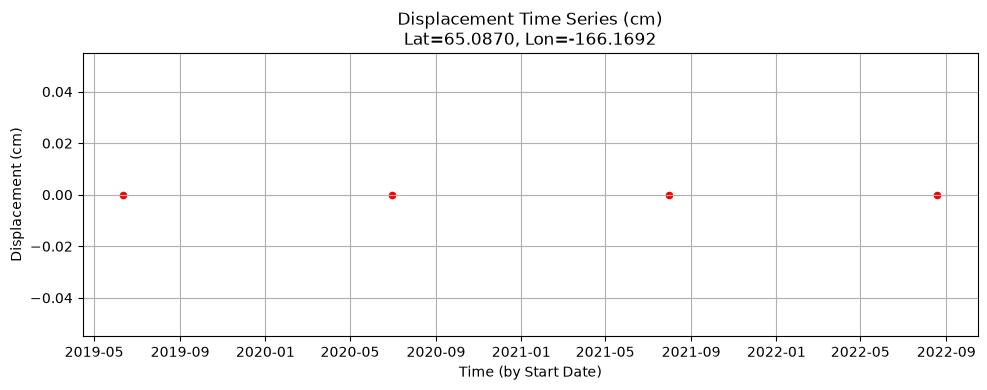

In [33]:
# Defines the point of interest
# (The reference point is used as an example here)
tslat = 65.086982 
tslon = -166.169205

is_latlon = stack_prod.x.values.max() < 360

if is_latlon:
    x_click, y_click = tslon, tslat
    dist_threshold = 0.001  # ~100 meters in decimal degrees
else:
    # Convert to UTM if the stack is in native meters
    proj = pyproj.Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
    x_click, y_click = proj.transform(tslon, tslat)
    dist_threshold = 100

# Find nearest grid point
x_coords = stack_prod.x.values
y_coords = stack_prod.y.values
x_nearest = x_coords[np.argmin(np.abs(x_coords - x_click))]
y_nearest = y_coords[np.argmin(np.abs(y_coords - y_click))]
distance = float(np.sqrt((x_click - x_nearest)**2 + (y_click - y_nearest)**2))

# Checks distance threshold
if distance > dist_threshold:
    print(f"Point too far from valid pixel (distance = {distance:.1f} m)")
else:
    # Check masks
    mask_val = stack_prod.sel(x=x_nearest, y=y_nearest, method="nearest").isel(time=-1).recommended_mask.values
    water_val = stack_prod.sel(x=x_nearest, y=y_nearest, method="nearest").isel(time=-1).water_mask.values

    if mask_val != 1 or water_val != 1:
        print("Selected point is masked out or on water.")
    else:
        # Get displacement
        disp = stack_prod.sel(x=x_nearest, y=y_nearest, method="nearest").displacement
        # Plot time series
        dates = pd.to_datetime(stack_prod.time.values)
        plt.figure(figsize=(10, 4))
        plt.scatter(dates, disp.values * 100, s=20, color='red')
        plt.title(f"Displacement Time Series (cm)\nLat={lat:.4f}, Lon={lon:.4f}")
        plt.xlabel("Time (by Start Date)")
        plt.ylabel("Displacement (cm)")
        plt.grid(True)
        plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        plt.tight_layout()
        plt.show()


## Inspect DISP-S1 Data Layers and their Attributes

This step prints detailed information about the variables contained in the DISP-S1 data stack.

For each variable (e.g., displacement, coherence, phase similarity), the function will display:
- The **data type**, and **description** of what the layer represents
- Units, if available
- Any relevant metadata or processing notes

In [34]:
variables = list(stack_prod.data_vars.items())

output_lines = []

for var_name, da in variables[3:]:
    output_lines.append(f"###  Layer: `{var_name}`")
    for attr_name, attr_val in da.attrs.items():
        output_lines.append(f"- **{attr_name}**: {attr_val}")
    output_lines.append("")  # empty line between variables

# Display once, in one cell
display(Markdown("\n".join(output_lines)))


###  Layer: `recommended_mask`
- **units**: unitless
- **similarity_threshold**: 0.6
- **temporal_coherence_threshold**: 0.7
- **estimated_phase_quality_threshold**: 0.1
- **uses_connected_component_labels**: False
- **description**: Suggested mask to remove low quality pixels, where 0 indicates a bad pixel, 1 is a good pixel. Pixels are set to 0 for three reasons: 1) the pixel is marked as water in /water_mask, 2) the pixel is 0 in /connected_component_labels, or 3) the pixel has low /temporal_coherence and low /phase_similarity, where 'low' is below the threshold listed in this dataset's attributes.
- **long_name**: Recommended Mask

###  Layer: `connected_component_labels`
- **units**: unitless
- **description**: Connected component labels of the unwrapped phase
- **long_name**: Connected Component Labels

###  Layer: `temporal_coherence`
- **units**: unitless
- **description**: Temporal coherence of phase inversion
- **long_name**: Temporal Coherence

###  Layer: `estimated_phase_quality`
- **units**: unitless
- **description**: Sliding window estimate of multi-looked phase noise
- **long_name**: Estimated phase quality

###  Layer: `persistent_scatterer_mask`
- **units**: unitless
- **description**: Mask of persistent scatterers downsampled to the multilooked output grid
- **long_name**: Persistent Scatterer Mask

###  Layer: `shp_counts`
- **units**: unitless
- **description**: Number of statistically homogeneous pixels (SHPs) used at each output pixel during multilooking
- **long_name**: Statistically Homogeneous Pixels Counts

###  Layer: `water_mask`
- **units**: unitless
- **description**: Binary mask created to ignore water during processing.
- **long_name**: Water Mask

###  Layer: `phase_similarity`
- **units**: unitless
- **description**: Median cosine similarity of wrapped phase in each pixel's neighborhood.
- **long_name**: Phase Similarity

###  Layer: `timeseries_inversion_residuals`
- **units**: radians
- **description**: Sum of residuals of the timeseries inversion for this secondary date.
- **long_name**: Timeseries inversion residuals


Variables in dataset: ['displacement', 'short_wavelength_displacement', 'recommended_mask', 'connected_component_labels', 'temporal_coherence', 'estimated_phase_quality', 'persistent_scatterer_mask', 'shp_counts', 'water_mask', 'phase_similarity', 'timeseries_inversion_residuals']


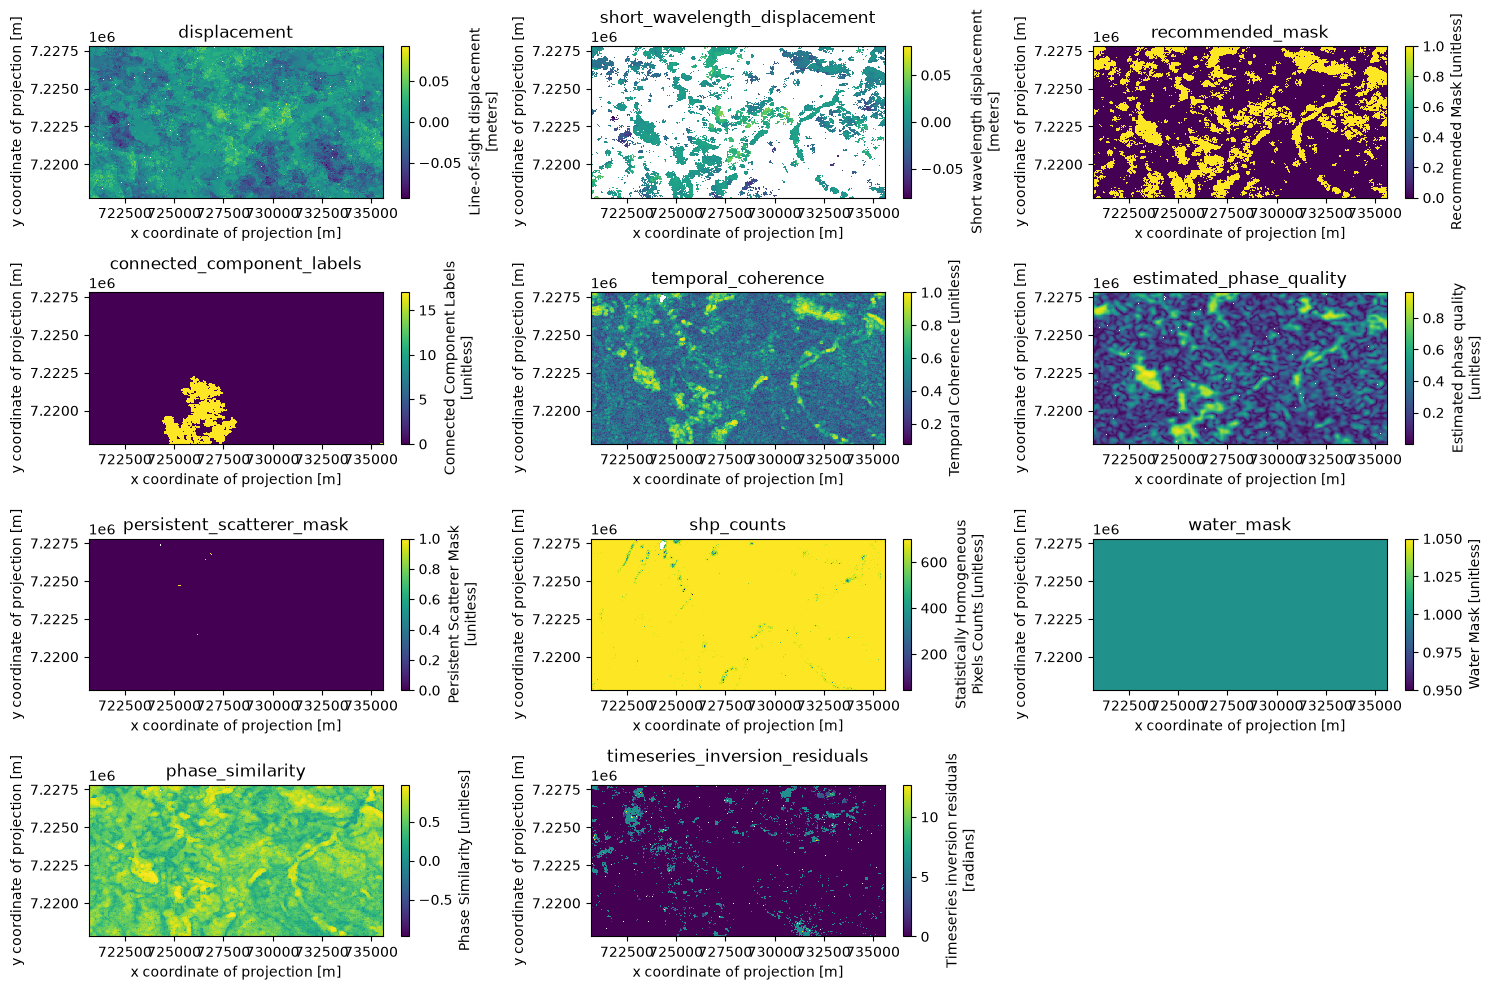

In [31]:
# List all data variables
variables = list(ds.data_vars.keys())
print(f"Variables in dataset: {variables[2:]}")

# Determine grid layout
num_vars = len(variables[2:])
grid_cols = int(num_vars ** 0.5)
grid_rows = (num_vars // grid_cols) + (num_vars % grid_cols > 0)

# Create a figure with subplots
fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(15, 10))
axes = axes.flatten()

# Loop through variables and plot
for i, var_name in enumerate(variables[2:]):
    data_ = ds[var_name]
    data_.plot(ax=axes[i], cmap="viridis", add_colorbar=True)
    axes[i].set_title(var_name)

# Hide unused subplots
for j in range(num_vars, len(axes)):
    axes[j].set_visible(False)

# Adjust layout and show
plt.tight_layout()
plt.show()

## Quality Metrics

The following step provides a summary of the **spatial quality** of the ministack by computing percentages of pixel characteristics:

- **% Persistent Scatterers (PS)**  
  The fraction of pixels identified as persistent scatterers, i.e., stable points that consistently reflect radar signals and are reliable for long-term displacement monitoring.

- **% Valid Time Series Pixels (recommended_mask)**  
  The proportion of pixels flagged as “good” by the recommended quality mask, combining multiple filters such as coherence, water masking, and phase similarity.

- **% Connected Component Valid (not 0)**  
  Indicates the portion of pixels that are part of a valid, unwrapped phase region (i.e., not isolated or ambiguous).

These percentages provide a diagnostic to assess the **spatial coverage and reliability** of the stack.

In [36]:
# Check for minimum time steps
stack_quality = stack_prod.chunk({'time': -1})
ref_dates, indices = np.unique(stack_quality.reference_time, return_index=True)
ministack_ref = stack_prod.isel(time=indices).chunk({'time': -1})
if ministack_ref.persistent_scatterer_mask.sizes["time"] <= 2:
    print("Not enough Ministacks steps to compute quality summary. At least 2 required.")

# Compute metrics
pct_ps = quality_metrics.get_value_percentage(ministack_ref.persistent_scatterer_mask.isel(time=slice(1, None)), value=1)
pct_mask = quality_metrics.get_value_percentage(ministack_ref.recommended_mask.isel(time=slice(1, None)), value=1, reverse=False)
pct_conncomp = quality_metrics.get_value_percentage(stack_quality.connected_component_labels.isel(time=slice(1, None)), value=0, reverse=True)
# Plot
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
im1 = ax[0].imshow(np.ma.masked_equal(pct_ps, 0), cmap='bone_r', clim=[0, 30], interpolation='nearest')
im2 = ax[1].imshow(np.ma.masked_equal(pct_mask, 0), cmap='plasma', clim=[0, 100], interpolation='nearest')
im3 = ax[2].imshow(np.ma.masked_equal(pct_conncomp, 0), cmap='afmhot_r', clim=[0, 100], interpolation='nearest')

for a, im in zip(ax, [im1, im2, im3]): fig.colorbar(im, ax=a, location='bottom')

for a, title in zip(ax, ['Pct of PS in stack','Timeseries density','Pct of valid conncomp']): a.set_title(title)

plt.tight_layout()
plt.show()

ValueError: Result from applying user function has unexpected coordinate variables {'spatial_ref', 'epsg'}.

This following step computes and displays quality indicators for the displacement stack based on metrics derived from the data:

- **Median Temporal Coherence**: Indicates the overall stability of the interferometric signal over time. Higher values suggest more reliable measurements.

- **Median Phase Similarity**: Reflects how consistent the phase is within local neighborhoods. Useful for identifying noisy or unstable areas.

- **Total Number of 2π Phase Jumps**: A diagnostic for phase unwrapping issues. A high count may indicate discontinuities or noise artifacts.

These metrics provide a summary of the stack’s integrity and can help you decide whether to proceed with or filter out unreliable areas.


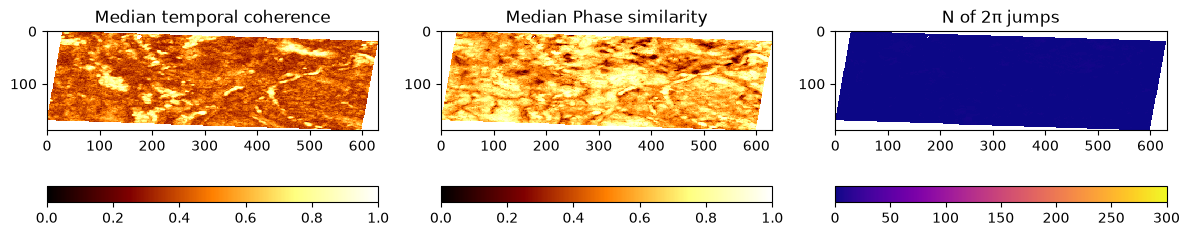

In [37]:
# Compute statistics
median_tcoh = quality_metrics.get_stack_stat(stack_quality.temporal_coherence.isel(time=slice(1, None)), mode='median')
median_psim = quality_metrics.get_stack_stat(stack_quality.phase_similarity.isel(time=slice(1, None)), mode='median')
inv_res_sum = quality_metrics.get_stack_stat(stack_quality.timeseries_inversion_residuals.isel(time=slice(1, None)), mode='sum')
num_2pi_jump = inv_res_sum / (2 * np.pi)

# Plot
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
im1 = ax[0].imshow(np.ma.masked_equal(median_tcoh, 0), cmap='afmhot', clim=[0, 1], interpolation='nearest')
im2 = ax[1].imshow(np.ma.masked_equal(median_psim, 0), cmap='afmhot', clim=[0, 1], interpolation='nearest')
im3 = ax[2].imshow(np.ma.masked_equal(num_2pi_jump, 0), cmap='plasma', clim=[0, 300], interpolation='nearest')

for a, im in zip(ax, [im1, im2, im3]): fig.colorbar(im, ax=a, location='bottom')

for a, title in zip(ax, ['Median temporal coherence', 'Median Phase similarity', 'N of 2π jumps']): a.set_title(title)

plt.tight_layout()
plt.show()


The following step computes and plots statistics related to **`shp_counts`**, which represent the number of statistically homogeneous pixels (SHPs) used in the multilooking process at each pixel.

For the selected ministack, this function reports:
- The median number of SHPs per pixel
- The standard deviation of SHP counts across the scene

These metrics help assess the robustness of the distributed scatterer (DS) processing:
- A higher median indicates more reliable local statistics
- High variability (standard deviation) may point to inconsistent signal quality across the scene

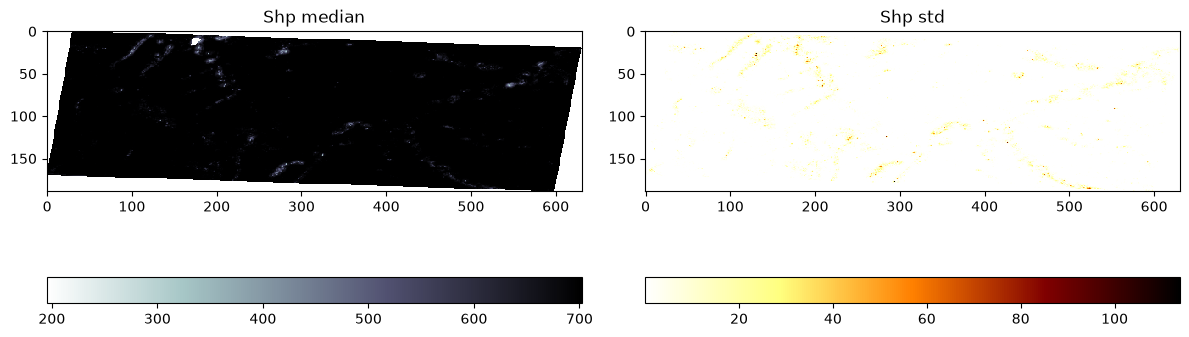

In [38]:
# Check for enough time steps
if ministack_ref.shp_counts.sizes.get("time", 0) <= 2:
    print("Not enough time steps to compute shp stats. At least 2 required.")

# Compute statistics
shp_median = quality_metrics.get_stack_stat(ministack_ref.shp_counts.isel(time=slice(1, None)), mode='median')
shp_std = quality_metrics.get_stack_stat(ministack_ref.shp_counts.isel(time=slice(1, None)), mode='std')

# Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
im1 = ax[0].imshow(np.ma.masked_equal(shp_median, 0), cmap='bone_r', interpolation='nearest')
im2 = ax[1].imshow(np.ma.masked_equal(shp_std, 0), cmap='afmhot_r', interpolation='nearest')

for a, im in zip(ax, [im1, im2]): fig.colorbar(im, ax=a, location='bottom')
for a, txt in zip(ax, ['Shp median', 'Shp std']): a.set_title(txt)
plt.tight_layout()
plt.show()

## Velocity Estimation

This cell computes a linear velocity map (in cm/year) from the displacement time series using least squares fitting.
- Fits a linear model: *displacement = velocity × time + intercept*.
- Colors represent motion in the satellite's line-of-sight (LOS) direction  
  - **Red** indicates motion **away** from the satellite  
  - **Blue** indicates motion **toward** the satellite

In [39]:
# Extract the displacement time series from stack_prod
disp = stack_prod['displacement'].values  # shape: (nt, ny, nx)
times = stack_prod['time'].values         # datetime64 array
ny, nx = disp.shape[1:]                   # spatial dimensions
nt = disp.shape[0]                        # number of time steps

# Convert time to decimal years
def _decimal_year(dates):
    """Convert datetime64 array to decimal years."""
    import pandas as pd
    dates = pd.to_datetime(dates)
    return dates.year + (dates.dayofyear - 1) / 365.25

tdecimal = _decimal_year(times)  # shape (nt,)
A = np.vstack([tdecimal, np.ones_like(tdecimal)]).T  # shape: (nt, 2)

# Reshape displacement to (nt, ny*nx)
y = disp.reshape(nt, -1)

# Solve least squares for linear fit: displacement = velocity * time + intercept
coef, *_ = np.linalg.lstsq(A, y, rcond=None)  # shape: (2, ny*nx)

# Extract velocity (slope) and reshape back to (ny, nx)
vel = coef[0].reshape(ny, nx).astype(np.float32)

# Create new DataArray in xarray
vel_da = xr.DataArray(vel, dims=("y", "x"), coords={"y": stack_prod.y, "x": stack_prod.x},
    attrs={
        "long_name": "Velocity",
        "units": "m/year",
        "description": "Linear velocity estimated from displacement time series",
        "start_date": str(times[0]),
        "end_date": str(times[-1]),
        "ref_date": str(times[0]),
    },
)

# Add it to a new dataset (or optionally merge with stack_prod)
velocity_ds = xr.Dataset({"velocity": vel_da})


In [40]:
# Convert velocity to cm/year and apply mask
vel_masked = (vel_da * 100).where((stack_prod.isel(time=-1).recommended_mask == 1) & (stack_prod.isel(time=-1).water_mask == 1))

# Reproject to EPSG:4326
vel_masked.rio.write_crs(epsg, inplace=True)
vel_masked.rio.set_spatial_dims(x_dim="x", y_dim="y", inplace=True)
vel_4326 = vel_masked.rio.reproject("EPSG:4326", resampling=rasterio.enums.Resampling.bilinear)

# Buffer bounds
buffer_fraction = 0.015
xmin, ymin, xmax, ymax = vel_4326.rio.bounds()
x_pad = (xmax - xmin) * buffer_fraction
y_pad = (ymax - ymin) * buffer_fraction
buffered_bounds = [xmin - x_pad, ymin - y_pad, xmax + x_pad, ymax + y_pad]
extent = [buffered_bounds[0], buffered_bounds[2], buffered_bounds[1], buffered_bounds[3]]

# Normalize values
v = np.nanpercentile(vel_4326.values, [2, 98])
vmax = max(abs(v[0]), abs(v[1]))
vmin = -vmax

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])

# Basemap
bg, bg_extent = get_baseimage_from_bounds(buffered_bounds, source=cx.providers.Esri.WorldImagery, grayscale=True, gamma=0.9)
ax.imshow(bg, extent=bg_extent, cmap="gray", origin="upper", zorder=1)

# Velocity overlay
im = ax.imshow( vel_4326.values, extent=[xmin, xmax, ymin, ymax], cmap="RdBu_r", vmin=vmin, vmax=vmax, alpha=0.6, origin="upper", zorder=2)

# Colorbar
cbar = plt.colorbar(im, ax=ax, shrink=0.6, pad=0.04)
cbar.set_label("Velocity [cm/year]")

# Ticks and formatting
ax.set_xticks(np.linspace(extent[0], extent[1], 5))
ax.set_yticks(np.linspace(extent[2], extent[3], 5))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{y:.2f}°N"))
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

# Attribution
ax.annotate(
    "Tiles © Esri — Sources: Esri, DigitalGlobe, GeoEye, i-cubed, USDA FSA, USGS, AEX, "
    "Getmapping, Aerogrid, IGN, IGP, swisstopo, and the GIS User Community",
    xy=(0.5, -0.12), xycoords='axes fraction',
    ha='center', va='top', fontsize=6, color='gray'
)

ax.set_title("OPERA DISP-S1 Estimated Velocity [cm/year]")
plt.tight_layout()
plt.show()


NameError: name 'epsg' is not defined

## Export DISP-S1 Stack for External Use
This final step prepares your displacement time series for export and use in other tools such as **MintPy**.

The process involves two main actions:

1. **Reformat DISP-S1 Files into a Single NetCDF Stack**  
   - Combines multiple DISP-S1 granules (from a ministack) into a single NetCDF file  
   - Uses a defined reference method (`NONE / MEDIAN / BORDER / POINT /  HIGH COHERENCE`) to re-reference all dates consistently  
   - Drops unnecessary variables like `connected_component_labels`, `shp_counts`, etc. to reduce file size  
   - Output: a single file named `disp-output-<frame_id>.nc`.

2. **Convert to MintPy Format**  
   - Uses the exported NetCDF to generate a MintPy-compatible displacement time series  
   - Produces outputs in the `export/` directory  

In [43]:
# -----------------------------
# DISP-S1 Stack Reformat Script
# -----------------------------

# Set the reference method to one of the following:
#   "NONE"            → No referencing (raw displacement)
#   "POINT"           → Reference to a specific lat/lon location
#   "MEDIAN"          → Median over valid land pixels (excludes water)
#   "BORDER"          → Median over border pixels (configurable size)
#   "HIGH_COHERENCE"  → Median over high-coherence mask (based on threshold)
REFERENCE_METHOD = "BORDER"  # <- Change this line to use a different method

# Output name based on frame ID
OUTPUT_NAME = f"disp-output.nc"

# Input files
INPUT_FILES = sorted(glob.glob("subset-ncs/*.nc"))
input_files_str = " ".join(INPUT_FILES)

# Execute the reformat command
!opera-utils disp-s1-reformat \
    --drop-vars connected_component_labels shp_counts persistent_scatterer_mask timeseries_inversion_residuals short_wavelength_displacement \
    --reference-method {REFERENCE_METHOD} \
    --output-name {OUTPUT_NAME} \
    --reference-border-pixels 3 \
    --input-files {input_files_str} \
    # Additional reference parameters (uncomment as needed):   
    #--reference-row {row} \
    #--reference-col {col} \
    #--reference-lat {lat} \
    #--reference-lon {lon} \     
    # --reference-coherence-threshold 0.7                      # For HIGH_COHERENCE method (default is 0.7

# Convert to MintPy
SAMPLE_FILE = INPUT_FILES[0]
!python -m opera_utils.disp.mintpy {OUTPUT_NAME} \
    --sample-disp-nc {SAMPLE_FILE} \
    --outdir export

!mv {OUTPUT_NAME} export/

Traceback (most recent call last):
  File "/sciclone/home/dfbunich/miniconda3/envs/opera_disp-s1/bin/opera-utils", line 6, in <module>
    sys.exit(cli_app())
             ^^^^^^^^^
  File "/sciclone/home/dfbunich/miniconda3/envs/opera_disp-s1/lib/python3.12/site-packages/opera_utils/cli.py", line 186, in cli_app
    tyro.extras.subcommand_cli_from_dict(
  File "/sciclone/home/dfbunich/miniconda3/envs/opera_disp-s1/lib/python3.12/site-packages/tyro/extras/_subcommand_cli_from_dict.py", line 125, in subcommand_cli_from_dict
    return cli(
           ^^^^
  File "/sciclone/home/dfbunich/miniconda3/envs/opera_disp-s1/lib/python3.12/site-packages/tyro/_cli.py", line 235, in cli
    output = _cli_impl(
             ^^^^^^^^^^
  File "/sciclone/home/dfbunich/miniconda3/envs/opera_disp-s1/lib/python3.12/site-packages/tyro/_cli.py", line 591, in _cli_impl
    get_out, consumed_keywords = _calling.callable_with_args(
                                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/sciclo

## Export for GIS & Quick-Look

The following code cell exports your DISP-S1 time series in two formats for further analysis or visualization:

- **Multi-band GeoTIFF Export**  
  A single GeoTIFF is created with one band per acquisition date. Each band contains cumulative displacement from the reference date to the corresponding acquisition.  
  This file can be opened in GIS software such as QGIS or ArcGIS Pro.

- **PNG Snapshots**  
  One PNG is generated per acquisition date to provide a quick visual overview of displacement evolution.  
  All images use a consistent, symmetric color scale centered on zero, determined from the final (most cumulative) image.

In [41]:
output_dir = "export"
displacement_var = "displacement"
input_nc = os.path.join(output_dir, OUTPUT_NAME)
output_tif = os.path.join(output_dir, f"OPERA-DISP-S1_Frame_{FRAME_ID}_displacement_timeseries.tif")

ds_full = xr.open_dataset(input_nc)
disp = ds_full[displacement_var]
dates = ds_full["time"].dt.strftime('%Y-%m-%dT%H:%M:%S').values

height, width = disp.shape[1], disp.shape[2]
transform = rasterio.transform.from_origin(ds_full.x[0], ds_full.y[0], np.abs(ds_full.x[1] - ds_full.x[0]), np.abs(ds_full.y[1] - ds_full.y[0]))
crs = ds_full.spatial_ref.attrs.get("crs_wkt") or ds_full.spatial_ref.attrs.get("spatial_ref")

with rasterio.open(output_tif, "w", driver="GTiff", count=disp.shape[0], height=height, width=width, dtype=disp.dtype, 
                   crs=crs, transform=transform, nodata=np.nan, compress="DEFLATE", tiled=True, predictor=2, bigtiff="YES", 
                   zlevel=4,) as dst:
    for i in range(disp.shape[0]):
        dst.write(disp[i, :, :].values.astype(np.float32), i + 1)

with rasterio.open(output_tif, "r+") as ds_edit:
    for i, date in enumerate(dates):
        ds_edit.set_band_description(i + 1, f"Time series: {date}")


NameError: name 'OUTPUT_NAME' is not defined

In [22]:
## Export PNGs for each time step
output_dir_pics = os.path.join(output_dir, "pics")
os.makedirs(output_dir_pics, exist_ok=True)
dates = ds_full["time"].dt.strftime('%Y%m%d').values
ref_date = ds_full['reference_time'].dt.strftime('%Y%m%d').values[0]

vmin_raw = np.nanpercentile(disp[-1], 1)
vmax_raw = np.nanpercentile(disp[-1], 99)
max_abs_val = max(abs(vmin_raw), abs(vmax_raw))
vmin, vmax = -max_abs_val, max_abs_val

file_paths = []
for i, date in enumerate(dates):
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(disp[i].values, cmap="jet", origin="upper", vmin=vmin, vmax=vmax)
    ax.set_title(f"OPERA-DISP-S1 Frame {FRAME_ID} -- Displacement from {dates[0]} to {date}")
    plt.colorbar(im, ax=ax, label="Displacement (m)")
    png_path = os.path.join(output_dir_pics, f"OPERA-DISP-S1_Frame_{FRAME_ID}_displacement_from_{ref_date}_to_{date}.png")
    plt.savefig(png_path, bbox_inches="tight")
    plt.close(fig)
    file_paths.append(png_path)

print(f'PNG Saved in /{output_dir_pics} directory')

PNG Saved in /export/pics directory


EOF